(mmm_multi_arm_geolift_calibration)=
# MMM Calibration with Multi-Arm Geo Lift Tests

A marketing team wants to learn how search advertising affects revenue, but cannot increase its overall test budget. Our geo test intervenes on **search spend only**: increase it in some geographic markets, decrease it in others, and leave a third group unchanged. Display advertising is the second modeled channel, but its spend is held fixed throughout the test. The unchanged markets help estimate what would have happened without the intervention. The two active arms reveal responses to spending more and spending less, even when their budget changes cancel.

This is useful when media budgets follow underlying demand: rising demand increases both spend and revenue, so an observational MMM can mistake that association for advertising response. It also helps when an MMM struggles to separate channels that usually move together. A geo experiment changes one channel independently, giving the MMM an additional constraint on its response curve. An up/down/control design supplies signed constraints at different spend levels across the population. Each treated market still contributes its own experiment contrast; combining them into one net lift would lose the information we want for calibration.

We work through that workflow for a synthetic retailer operating in **48 geographic markets, labeled with the contiguous US states**. Sixteen markets increase search spend, sixteen decrease it, and sixteen act as controls. We work through two steps: **synthetic controls** estimate experimental geo-level effects with CausalPy, then a **hierarchical geo MMM** uses those estimates for calibration. We fit the MMM with and without calibration, deliberately omitting latent demand from both, and check recovery against known truth. These are two stages of one workflow, rather than competing estimates of the same quantity.

We keep the simulated business deliberately simple so we can focus on setting up the geo test, estimating lift, and passing those estimates into MMM calibration. The two channels have stable response curves and no carryover; the controlled budget setup makes the experiment contrasts easy to follow.

The labels use [Census state codes](https://cdn.www.census.gov/library/reference/code-lists/ansi/ansi-codes-for-states.html). Market sizes, assignments, spend, response parameters, and revenue are all simulated; the state names do not imply realistic state populations or market economics. These are state-level markets, not DMAs.

| Arm | Markets | Planned search change per market | Delivered change | Expected effect |
|---|---:|---:|---:|---|
| Up | 16 | +8,000 USD/week | +7,200 USD/week | Positive |
| Down | 16 | −8,000 USD/week | −7,200 USD/week | Negative |
| Control | 16 | 0 | 0 | Zero |

Equal delivered increases and decreases make this example **spend-neutral**. They need not make it revenue-neutral: different markets can have different responses to the same change in spend. We will inspect both the individual effects used for calibration and their net revenue effect.

This extends {ref}`mmm_geolift_calibration` and assumes familiarity with {ref}`mmm_multidimensional_example` and [CausalPy's up/down/control example](https://causalpy.readthedocs.io/en/latest/notebooks/up-down-control-geolift-pymc.html). We use a supplied assignment to focus on estimation and calibration; selecting or optimizing real experiment markets is outside this walkthrough.

## Setup and data-generating process

The data-generating process is a teaching example, rather than a realistic retailer simulator. We use just two channels, **search and display**, with geo-specific logistic response curves, shared seasonality, and no carryover.

A shared, unobserved **demand index** raises historical search budgets and revenue directly. Display has budget variation independent of demand, while a shared local budget factor still correlates the channels. Latent demand is included in the simulation but deliberately omitted from both fitted MMMs. Its shared influence on historical search spend and revenue creates a backdoor path that neither MMM directly adjusts for, giving calibration a causal task beyond separating correlated channels.

:::{dropdown} Optional: reproduce the repository environment

From a checkout of this repository, `uv sync --locked --extra docs --extra test` installs the versions recorded in `uv.lock`, including documentation tools, CausalPy's exporter, and the notebook execution tools in the test extra. This is environment setup, not part of estimating lift or fitting an MMM. If that environment is already active, skip this command. The causal diagram also needs the Graphviz `dot` executable on your system.

```bash
uv sync --locked --extra docs --extra test
```
:::


In [1]:
import logging
import time

import arviz as az
import causalpy as cp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import pymc as pm
import pytensor.xtensor as ptx
import xarray as xr
from graphviz import Digraph
from IPython.display import HTML, SVG, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from pymc_extras.prior import Prior

from pymc_marketing.mmm import MMM, LogisticSaturation, NoAdstock
from pymc_marketing.mmm.scaling import FixedScaling, Scaling
from pymc_marketing.mmm.transformers import logistic_saturation

%matplotlib inline
# Store Matplotlib figures at double pixel density for sharp documentation output.
%config InlineBackend.figure_format = "retina"
logging.getLogger("pymc").setLevel(logging.WARNING)
FIG_WIDTH, FIG_HEIGHT = 10, 3.5
COLOR_UP, COLOR_DOWN, COLOR_CONTROL = "#0072B2", "#D55E00", "#777777"
COLOR_NET = "#7B3294"
COLOR_DONOR = "#87929D"
CHANNEL_COLORS = {"search": "#0072B2", "display": "#009E73"}
ARM_COLORS = {"up": COLOR_UP, "down": COLOR_DOWN, "control": COLOR_CONTROL}
plt.rcParams.update(
    {
        "figure.figsize": (FIG_WIDTH, FIG_HEIGHT),
        "font.size": 12,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)
USD = StrMethodFormatter("${x:,.0f}")
SEED = sum(map(ord, "Signed multi-arm geo calibration"))
streams = np.random.SeedSequence(SEED).spawn(5)
rng_parameters, rng_spend, rng_history, rng_experiment, rng_assignment = [
    np.random.default_rng(s) for s in streams
]
SCALE = 100_000.0
channels = ["search", "display"]
started = time.perf_counter()

The equation below defines the **simulation truth** used to generate revenue, including latent demand $D_t$. For geo $g$ and week $t$,

$$
\begin{aligned}
Y_{gt} &= a_g+\sum_c f_{gc}(X_{gtc})+s_t+10{,}000 D_t+\epsilon_{gt},\\
f_{gc}(x) &= 100{,}000\beta_{gc}\tanh\!\left(\frac{\lambda_{gc}x}{2\times100{,}000}\right).
\end{aligned}
$$

The sum runs over search and display; $a_g$ is baseline revenue in USD/week. Here $D_t$ is a smooth, standardized common demand index, $s_t$ is shared annual seasonality, and observation noise has SD 1,000 USD/week. Historical search budgets increase with demand; display budget variation is independent of demand, and both channels also share smooth local budget fluctuations.

Both fitted MMMs use spend and seasonality but deliberately exclude $D_t$. This lets us test whether experimental calibration improves causal lift estimates despite an omitted confounder. Calibration adds experimental lift constraints; it does not add $D_t$ as a model input or guarantee complete removal of its bias. Knowing the simulation truth lets us measure attribution error; in practice, a credible observed demand control should be included rather than deliberately omitted.

We use **all 136 pre-intervention weeks for MMM training**. The last 32 also fit CausalPy's donor weights, followed by an eight-week intervention. These periods need not be disjoint. Reusing the donor-fit outcomes makes the two-stage estimates dependent; the marginal calibration likelihood below does not model that dependence. We keep intervention outcomes out of the ordinary MMM target likelihood so the same realized lift is not also supplied directly as a target observation. Including them would require additional care about reused evidence, not a different response-curve API.

During the 40-week donor/experiment panel, business-as-usual spend is constant and only the assigned search dose changes. This deliberate policy change makes the scalar saturation contrast exact. It also explains why the revenue plot becomes less volatile at the dotted line: variable budgets stop, while demand, seasonality, and observation noise continue. It is a simulation simplification, not a required feature of geo tests.

In [2]:
geos = (
    "AL AZ AR CA CO CT DE FL GA ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT "
    "NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY"
).split()
geos = sorted(geos)
G = len(geos)
# Select an illustrative donor pool before randomizing the active doses.
donor_geos = geos[::3]
dates = pd.date_range("2022-01-03", periods=144, freq="W-MON")
train_dates, estimation_dates = dates[:136], dates[104:]
experiment_start, experiment_end = dates[136], dates[-1]
window = estimation_dates[estimation_dates >= experiment_start]
true_lam = rng_parameters.lognormal(np.log([4.0, 3.0]), 0.12, (G, 2))
true_beta = rng_parameters.lognormal(np.log([0.6, 0.5]), 0.12, (G, 2))
true_intercept = rng_parameters.uniform(0.50, 0.70, G)
true_intercept[[geos.index(g) for g in donor_geos]] = np.linspace(
    0.20, 1.00, len(donor_geos)
)
base_spend = rng_spend.uniform(32_000, 48_000, (G, 2))
# Market properties are fixed before treatment assignment. Controls are selected,
# not randomized; only the 32 experimental markets receive randomized up/down doses.
experimental_geos = [g for g in geos if g not in donor_geos]
assigned = rng_assignment.permutation(experimental_geos).tolist()
arm_size = len(geos) // 3
arms = {
    "up": sorted(assigned[:arm_size]),
    "down": sorted(assigned[arm_size:]),
    "control": donor_geos,
}
geo_arm = {g: arm for arm, members in arms.items() for g in members}


# Smooth, shared latent demand drives search budgets and non-media revenue.
# It is intentionally omitted from both fitted MMMs.
def smooth_process(shape, persistence=0.85):
    values = rng_spend.normal(size=shape)
    for t in range(1, shape[0]):
        values[t] = (
            persistence * values[t - 1] + np.sqrt(1 - persistence**2) * values[t]
        )
    return (values - values.mean(axis=0)) / values.std(axis=0)


latent_demand = smooth_process((144,))
local_budget = smooth_process((104, G, 1))
historical_spend = base_spend[None, :, :] * (
    1 + latent_demand[:104, None, None] * np.array([0.18, 0.0]) + 0.08 * local_budget
) + rng_spend.normal(0, 1_500, (104, G, 2))
DEMAND_EFFECT = 10_000.0  # Direct revenue change (USD/week) per SD of demand.
baseline = np.broadcast_to(base_spend, (40, G, 2)).copy()
planned = baseline.copy()
for arm, sign in [("up", 1), ("down", -1)]:
    planned[32:, [geos.index(g) for g in arms[arm]], 0] += sign * 8_000
realized = baseline + 0.9 * (planned - baseline)
season_controls = np.column_stack(
    [np.sin(2 * np.pi * np.arange(144) / 52), np.cos(2 * np.pi * np.arange(144) / 52)]
)
true_gamma = np.array([0.06, 0.03])


def media_response(spend):
    x = ptx.as_xtensor(spend / SCALE, dims=("time", "geo", "channel"))
    lam = ptx.as_xtensor(true_lam, dims=("geo", "channel"))
    saturated = (
        logistic_saturation(x, lam=lam).transpose("time", "geo", "channel").eval()
    )
    return (true_beta * saturated).sum(axis=-1) * SCALE


mu_history = (
    SCALE * (true_intercept + season_controls[:104] @ true_gamma[:, None])
    + media_response(historical_spend)
    + DEMAND_EFFECT * latent_demand[:104, None]
)
mu_baseline = (
    SCALE * (true_intercept + season_controls[104:] @ true_gamma[:, None])
    + media_response(baseline)
    + DEMAND_EFFECT * latent_demand[104:, None]
)
mu_experiment = (
    SCALE * (true_intercept + season_controls[104:] @ true_gamma[:, None])
    + media_response(realized)
    + DEMAND_EFFECT * latent_demand[104:, None]
)
y_history = mu_history + rng_history.normal(0, 1_000, mu_history.shape)
y_experiment = mu_experiment + rng_experiment.normal(0, 1_000, mu_experiment.shape)
true_lift = pd.Series((mu_experiment - mu_baseline)[32:].mean(axis=0), index=geos)

In [3]:
def long_features(spend, selected_dates, controls):
    frame = pd.DataFrame(spend.reshape(-1, 2), columns=channels)
    frame["date"] = np.repeat(selected_dates, G)
    frame["geo"] = np.tile(geos, len(selected_dates))
    frame[["annual_sin", "annual_cos"]] = np.repeat(controls, G, axis=0)
    return frame


# Retain all 136 pre-intervention weeks, including the 32 donor-fit weeks.
training_spend = np.concatenate([historical_spend, realized[:32]])
X_train = long_features(training_spend, train_dates, season_controls[:136])
y_train = pd.Series(np.vstack([y_history, y_experiment[:32]]).ravel(), name="revenue")
experiment_revenue = pd.DataFrame(y_experiment, index=estimation_dates, columns=geos)
spend_columns = pd.MultiIndex.from_product([geos, channels], names=["geo", "channel"])
spend_baseline = pd.DataFrame(
    baseline.reshape(40, -1), index=estimation_dates, columns=spend_columns
)
spend_realized = pd.DataFrame(
    realized.reshape(40, -1), index=estimation_dates, columns=spend_columns
)
for frame in (experiment_revenue, spend_baseline, spend_realized):
    frame.attrs["unit"] = "USD/week"
np.testing.assert_equal(len(set(geos)), 48)
np.testing.assert_equal([len(arms[a]) for a in arms], [16, 16, 16])
np.testing.assert_equal(len(train_dates.intersection(estimation_dates)), 32)
if train_dates.max() >= experiment_start:
    raise ValueError("MMM target dates must precede the intervention.")
np.testing.assert_array_equal(realized[:, :, 1], baseline[:, :, 1])
np.testing.assert_array_equal(
    realized[:, [geos.index(g) for g in arms["control"]]],
    baseline[:, [geos.index(g) for g in arms["control"]]],
)
for values in (historical_spend, baseline, realized, y_history, y_experiment):
    if not np.isfinite(values).all() or values.min() <= 0:
        raise ValueError("The simulation must have finite positive spend and revenue.")

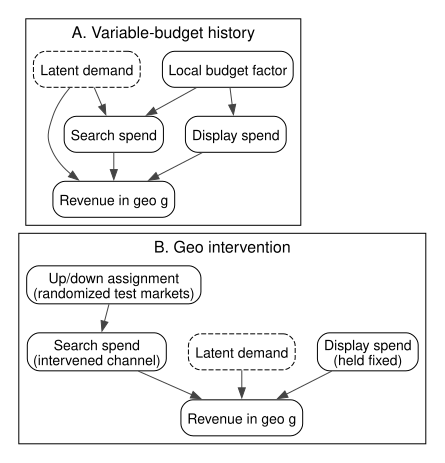

In [4]:
dag = Digraph("calibration_dgp")
dag.attr(rankdir="TB", bgcolor="white", nodesep="0.3", ranksep="0.4", pad="0.15")
dag.attr("node", shape="box", style="rounded", fontname="Helvetica", fontsize="14")
dag.attr("edge", color="#444444")

with dag.subgraph(name="cluster_history") as history:
    history.attr(
        label="A. Variable-budget history", fontname="Helvetica", fontsize="16"
    )
    history.node("h_demand", "Latent demand", style="rounded,dashed")
    history.node("h_budget", "Local budget factor")
    history.node("h_search", "Search spend")
    history.node("h_display", "Display spend")
    history.node("h_revenue", "Revenue in geo g")
    history.edges(
        [
            ("h_demand", "h_search"),
            ("h_demand", "h_revenue"),
            ("h_budget", "h_search"),
            ("h_budget", "h_display"),
            ("h_search", "h_revenue"),
            ("h_display", "h_revenue"),
        ]
    )

with dag.subgraph(name="cluster_experiment") as experiment:
    experiment.attr(label="B. Geo intervention", fontname="Helvetica", fontsize="16")
    experiment.node("e_assignment", "Up/down assignment\n(randomized test markets)")
    experiment.node("e_demand", "Latent demand", style="rounded,dashed")
    experiment.node("e_search", "Search spend\n(intervened channel)")
    experiment.node("e_display", "Display spend\n(held fixed)")
    experiment.node("e_revenue", "Revenue in geo g")
    experiment.edges(
        [
            ("e_assignment", "e_search"),
            ("e_search", "e_revenue"),
            ("e_display", "e_revenue"),
            ("e_demand", "e_revenue"),
        ]
    )

# Stack the two regimes; this invisible edge only controls layout.
dag.edge("h_revenue", "e_assignment", style="invis")
display(SVG(dag.pipe(format="svg")))

**Caption:** Simplified causal DAGs for the same geo-level revenue outcome under two spending regimes, conditional on geo-specific baselines, response parameters, and observed seasonality. In panel A, latent demand confounds the search–revenue relationship. In panel B, randomized up/down assignment changes search spend, which changes revenue; there is no direct assignment-to-revenue effect. Dashed nodes mark latent demand, which is omitted from both fitted MMMs.

Each panel has one revenue node: treated and control markets follow the same revenue equation. Display spend stays fixed during the test. Demand still affects revenue in every market, giving the untreated donors a shared signal for synthetic control, but no longer drives search budgets during the fixed-budget donor/experiment period. The two panels separate that policy change from the historical confounding path.

Selecting and assigning geos to arms is an important part of designing a credible geo test, but it is a topic of its own and outside this walkthrough's focus on estimation and calibration. Here we select an illustrative donor pool with deliberately broad baseline revenues, then randomize the remaining 32 markets between up and down doses. Controls are selected, not randomized, and all market properties are fixed before active-dose assignment. This makes donor support plausible; we still check the pre-intervention fit below.

In [5]:
from plotly.subplots import make_subplots

observed_revenue = pd.DataFrame(
    np.vstack([y_history, y_experiment]), index=dates, columns=geos
)
geo_figure = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.16,
    subplot_titles=("Individual markets", "Mean across markets in each arm"),
)
geo_figure.update_annotations(x=0, xanchor="left", font={"size": 14})
for arm, members in arms.items():
    for i, geo in enumerate(members):
        geo_figure.add_trace(
            go.Scatter(
                x=dates,
                y=observed_revenue[geo],
                mode="lines",
                line={"color": ARM_COLORS[arm], "width": 2},
                opacity=0.8,
                name=f"{arm.title()} ({len(members)} markets)",
                legendgroup=arm,
                showlegend=i == 0,
                meta=[geo, arm],
                hovertemplate=(
                    "<b>%{meta[0]}</b> · %{meta[1]} arm"
                    "<br>Week: %{x|%d %b %Y}"
                    "<br>Revenue: $%{y:,.0f} USD/week<extra></extra>"
                ),
            ),
            row=1,
            col=1,
        )
    geo_figure.add_trace(
        go.Scatter(
            x=dates,
            y=observed_revenue[members].mean(axis=1),
            mode="lines",
            line={"color": ARM_COLORS[arm], "width": 3},
            name=f"{arm.title()} mean",
            legendgroup=arm,
            showlegend=False,
            meta=[arm, len(members)],
            hovertemplate=(
                "<b>%{meta[0]} arm mean</b> · %{meta[1]} markets"
                "<br>Week: %{x|%d %b %Y}"
                "<br>Mean revenue: $%{y:,.0f} USD/week per market<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )
geo_figure.add_vline(
    x=estimation_dates[0].to_pydatetime(), line_dash="dot", line_color=COLOR_DONOR
)
geo_figure.add_vline(
    x=experiment_start.to_pydatetime(), line_dash="dash", line_color="black"
)
geo_figure.add_annotation(
    x=experiment_start,
    y=1.045,
    yref="paper",
    text="Intervention",
    showarrow=False,
    xanchor="right",
)
geo_figure.add_annotation(
    x=estimation_dates[0],
    y=1.045,
    yref="paper",
    text="Budgets fixed for donor fit",
    showarrow=False,
    xanchor="right",
)
geo_figure.update_layout(
    template="plotly_white",
    autosize=True,
    height=int(FIG_HEIGHT * 100 * 2.3),
    margin={"l": 85, "r": 20, "t": 110, "b": 55},
    font={"size": 13},
    hovermode="closest",
    hoverlabel={"bgcolor": "white", "font": {"color": "#222222"}},
    legend={"orientation": "h", "y": 1.14, "x": 0},
)
geo_figure.update_xaxes(tickformat="%b %Y", nticks=6)
geo_figure.update_xaxes(title_text="Week", row=2, col=1)
geo_figure.update_yaxes(tickprefix="$", tickformat=",.0f")
geo_figure.update_yaxes(title_text="Market revenue (USD/week)", row=1, col=1)
geo_figure.update_yaxes(title_text="Mean market revenue (USD/week)", row=2, col=1)
display(
    HTML(
        geo_figure.to_html(
            full_html=False,
            include_plotlyjs="cdn",
            config={"responsive": True, "displaylogo": False},
            post_script="""
        const plot = document.getElementById('{plot_id}');
        let previousWidth = 0;
        const observer = new ResizeObserver(([entry]) => {
            const width = entry.contentRect.width;
            if (width > 0 && width !== previousWidth) {
                previousWidth = width;
                Plotly.Plots.resize(plot);
            }
        });
        observer.observe(plot.parentElement);
        """,
        )
    )
)

**Caption:** Observed weekly revenue by market (top) and the arithmetic mean across markets within each arm (bottom), colored by up, down, and control arm. The panels share the time axis and use separate revenue ranges to show individual variation and group means. Hover identifies each market or arm mean, week, and revenue in USD/week per market. The dotted lines mark fixed baseline budgets and the start of donor fitting; the black dashed lines start intervention. Both periods before intervention enter MMM training.

In [6]:
historical_correlations = (
    X_train.query("date < @estimation_dates[0]")
    .groupby("geo")[channels]
    .corr()
    .loc[(slice(None), "search"), "display"]
)
display(historical_correlations.describe().to_frame("Historical channel correlation"))

,Historical channel correlation
count,48.000000
mean,0.334707
std,0.210192
min,-0.137308
25%,0.194708
50%,0.362533
75%,0.516776
max,0.684270


The variable-budget history contains correlated channels because they share local budget changes. Search also tracks latent demand; display does not. The association is partly noncausal: demand also raises revenue without passing through media. The next section creates spend changes by assignment instead of following demand; unchanged markets retain the common demand signal used to estimate untreated revenue.

### A spend-neutral intervention

Equal planned increases and decreases receive the same 90% delivery fraction. We verify neutrality from the delivered panel rather than assuming planned spend was delivered. Each geo retains its own baseline and signed change.

,planned,delivered
up,"$128,000","$115,200"
down,"$-128,000","$-115,200"
control,$0,$0
net,$0,$0


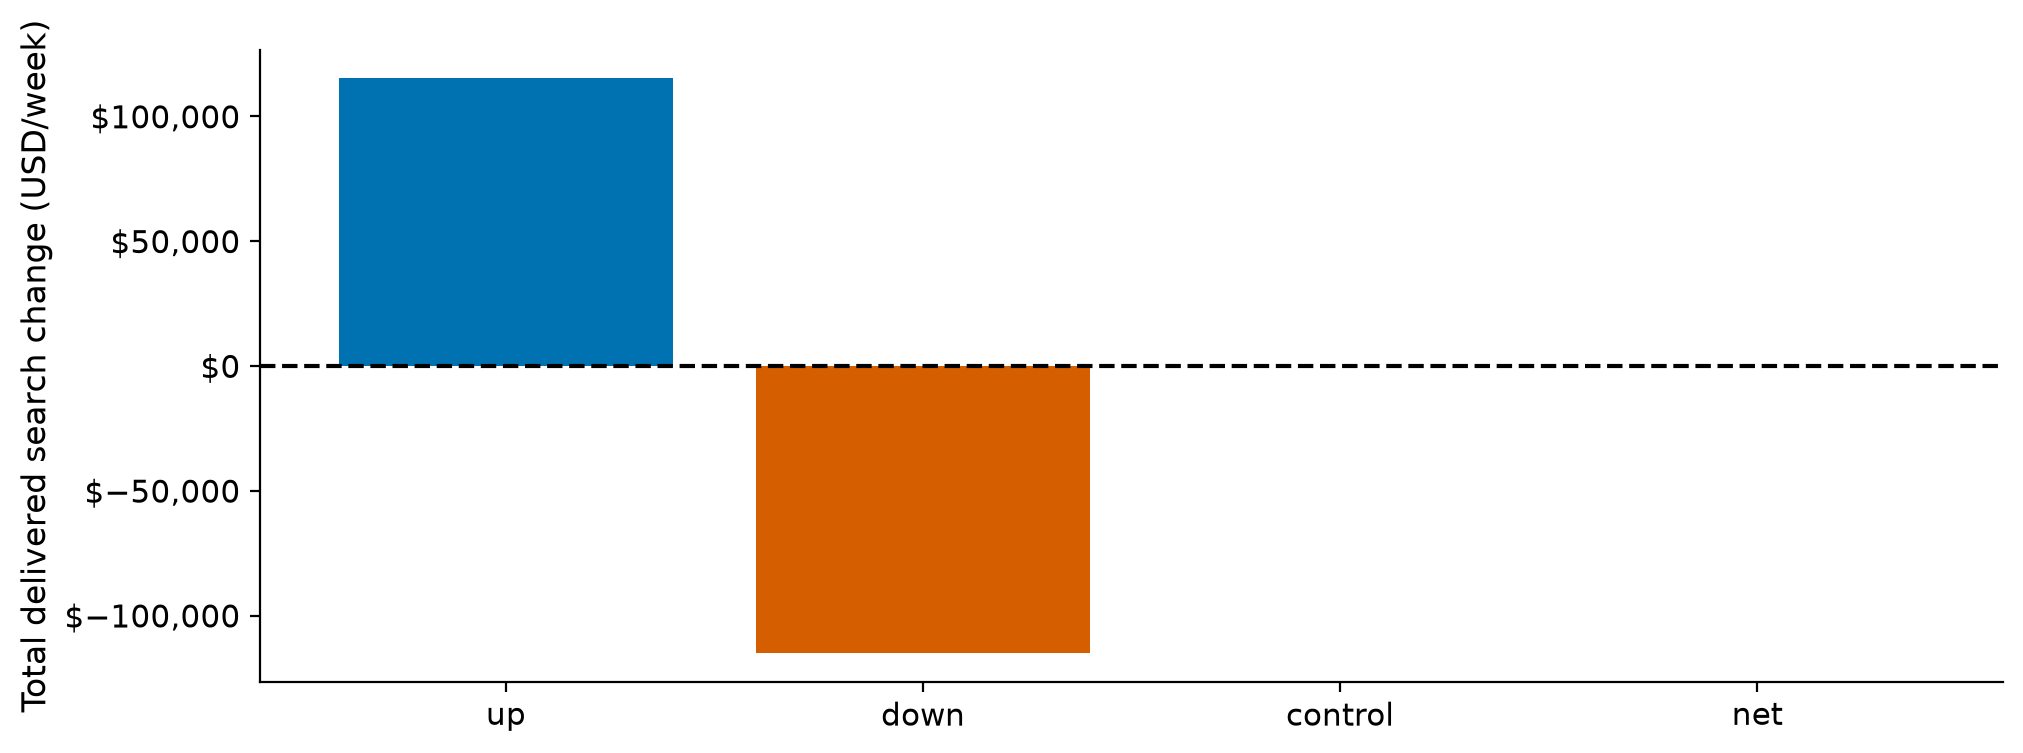

In [7]:
accounting = pd.DataFrame(index=["up", "down", "control"])
for label, panel in [("planned", planned), ("delivered", realized)]:
    accounting[label] = [
        (panel - baseline)[32:, [geos.index(g) for g in arms[a]], 0].sum(axis=1).mean()
        for a in accounting.index
    ]
accounting.loc["net"] = accounting.sum()
for panel in (planned, realized):
    np.testing.assert_allclose((panel - baseline)[32:, :, 0].sum(axis=1), 0, atol=1e-8)
np.testing.assert_allclose(np.ptp(baseline[32:], axis=0), 0, atol=1e-8)
np.testing.assert_allclose(np.ptp((realized - baseline)[32:], axis=0), 0, atol=1e-8)
representatives = {
    a: sorted(arms[a], key=lambda g: base_spend[geos.index(g), 0])[arm_size // 2]
    for a in arms
}
display(accounting.style.format("${:,.0f}"))
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
ax.bar(
    accounting.index,
    accounting.delivered,
    color=[COLOR_UP, COLOR_DOWN, COLOR_CONTROL, "black"],
)
ax.axhline(0, color="black", linestyle="--")
ax.set_ylabel("Total delivered search change (USD/week)")
ax.yaxis.set_major_formatter(USD)
plt.show()

**Caption:** Delivered weekly search changes summed across markets in each arm and across the experiment. The planned increases and decreases offset, and the delivered changes leave total search spend unchanged.

Spend neutrality does not imply outcome neutrality: a dollar added in one geo need not generate as much revenue as a dollar removed elsewhere would lose. Geos have different response curves and baseline spend, so their marginal returns differ; diminishing returns also make equal increases and decreases asymmetric. Market size can contribute in practice, but baseline revenue alone cancels from this simulation's additive lift contrast. Representative markets below are selected by median baseline search spend before inspecting estimated effects.

## Step 1: estimate experimental lift with synthetic controls

CausalPy constructs each treated market's missing **no-intervention revenue path** as a weighted combination of unchanged control markets. Donor weights are learned from the 32 pre-intervention weeks with fixed budgets, then applied during the eight-week intervention. Observed revenue minus that counterfactual is the signed impact. One joint fit estimates all treated markets; neither active arm supplies donors to the other.

Demand enters every market additively, and the selected donor pool spans a broad range of baseline levels. Donor combinations can therefore carry the shared demand and seasonality signal into the counterfactual. Identification still requires stable relationships, adequate pre-period fit, no spillovers, and no concurrent market-specific changes correlated with assignment. Randomizing active doses alone does not verify those counterfactual assumptions. We use two chains with 1,000 retained draws each and hide sampling progress.

In [8]:
sc_fit_kwargs = dict(
    tune=1_000,
    draws=1_000,
    chains=2,
    cores=2,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED + 10,
    progressbar=False,
)
mmm_fit_kwargs = dict(
    tune=2_000,
    draws=2_000,
    chains=2,
    cores=2,
    nuts_sampler="nutpie",
    random_seed=SEED + 20,
    progressbar=False,
    nuts={
        "target_accept": 0.99,
        "adaptation": "low_rank",
        "mass_matrix_eigval_cutoff": 3,
    },
)
result = cp.UpDownGeoLift(
    experiment_revenue,
    treatment_time=experiment_start,
    arms=arms,
    model=cp.pymc_models.SoftmaxWeightedSumFitter(sample_kwargs=sc_fit_kwargs),
).fit()

In [9]:
lift_rows = result.to_mmm_lift(
    spend_baseline=spend_baseline,
    spend_realized=spend_realized,
    channel="search",
    spend_unit="USD/week",
    outcome_unit="USD/week",
    start=experiment_start,
    end=experiment_end,
)
np.testing.assert_equal(len(lift_rows), 32)
np.testing.assert_equal(set(lift_rows.geo), set(arms["up"] + arms["down"]))
if (
    not np.isfinite(lift_rows[["delta_y", "sigma"]]).all().all()
    or not (lift_rows.sigma > 0).all()
):
    raise ValueError("Exported effects and uncertainties must be valid.")
np.testing.assert_array_equal(np.sign(lift_rows.delta_x), np.sign(lift_rows.delta_y))
display(
    lift_rows[["geo", "arm", "channel", "x", "delta_x", "delta_y", "sigma"]]
    .groupby("arm", sort=False)
    .head(2)
    .style.format({c: "{:,.1f}" for c in ["x", "delta_x", "delta_y", "sigma"]})
)

,geo,arm,channel,x,delta_x,delta_y,sigma
0,AZ,up,search,"42,195.5","7,200.0","3,273.7",186.9
1,CT,up,search,"37,054.7","7,200.0","4,500.4",165.0
16,AR,down,search,"38,137.2","-7,200.0","-6,149.0",207.3
17,CO,down,search,"32,544.1","-7,200.0","-6,722.7",177.8


The exported values below all describe the same inclusive weekly window. Confirm that spend and outcome units match before supplying the rows to an MMM.

In [10]:
display(
    lift_rows[
        ["window_start", "window_end", "n_periods", "spend_unit", "outcome_unit"]
    ].drop_duplicates()
)

,window_start,window_end,n_periods,spend_unit,outcome_unit
0,2024-08-12,2024-09-30,8,USD/week,USD/week


These are fitted estimates, not the true effects. `x` is that geo's mean business-as-usual search spend; `delta_x` is delivered minus business-as-usual spend. Thus `x + delta_x` is delivered spend, below baseline for a down geo and above it for an up geo. `delta_y` is the posterior mean of mean weekly impact. `sigma` is the posterior SD of that time-averaged impact: do not divide it by √8 again. All four quantities are in USD/week.

The exporter currently rejects estimates whose sign disagrees with delivered spend. That is an exporter restriction; the MMM's signed Normal likelihood can accept noisy discordant observations. We preserve all 32 exported geos without flipping, clipping, or replacing estimates.

In [11]:
pre_residual = result.result.impact_pre
pre_rmse = np.sqrt((pre_residual.mean(["chain", "draw"]) ** 2).mean("obs_ind"))
pre_table = pre_rmse.to_series().rename("Pre-fit RMSE (USD/week)").to_frame()
pre_table["arm"] = [geo_arm[g] for g in pre_table.index]
pre_table = pre_table.sort_values(["arm", "Pre-fit RMSE (USD/week)"])
display(
    HTML(
        '<details class="admonition note">'
        "<summary><strong>Optional diagnostic: pre-intervention donor fit</strong></summary>"
        "<p>RMSE summarizes the pre-intervention residuals for every treated market, in USD/week. "
        "A poor fit is a reason to investigate the donor model. A good in-sample fit does not "
        "establish that post-intervention counterfactual assumptions hold.</p>"
        + pre_table.style.format({"Pre-fit RMSE (USD/week)": "${:,.0f}"}).to_html()
        + "</details>"
    )
)

,Pre-fit RMSE (USD/week),arm
treated_units,,
GA,$744,down
MT,$763,down
CO,$817,down
KY,$851,down
MI,$888,down
FL,$927,down
TX,$965,down
MA,$968,down
MD,$968,down


The optional diagnostic above checks pre-intervention fit for every treated market. The next figure shows observed outcomes, estimated counterfactuals, and signed impacts for the two predetermined representative markets.

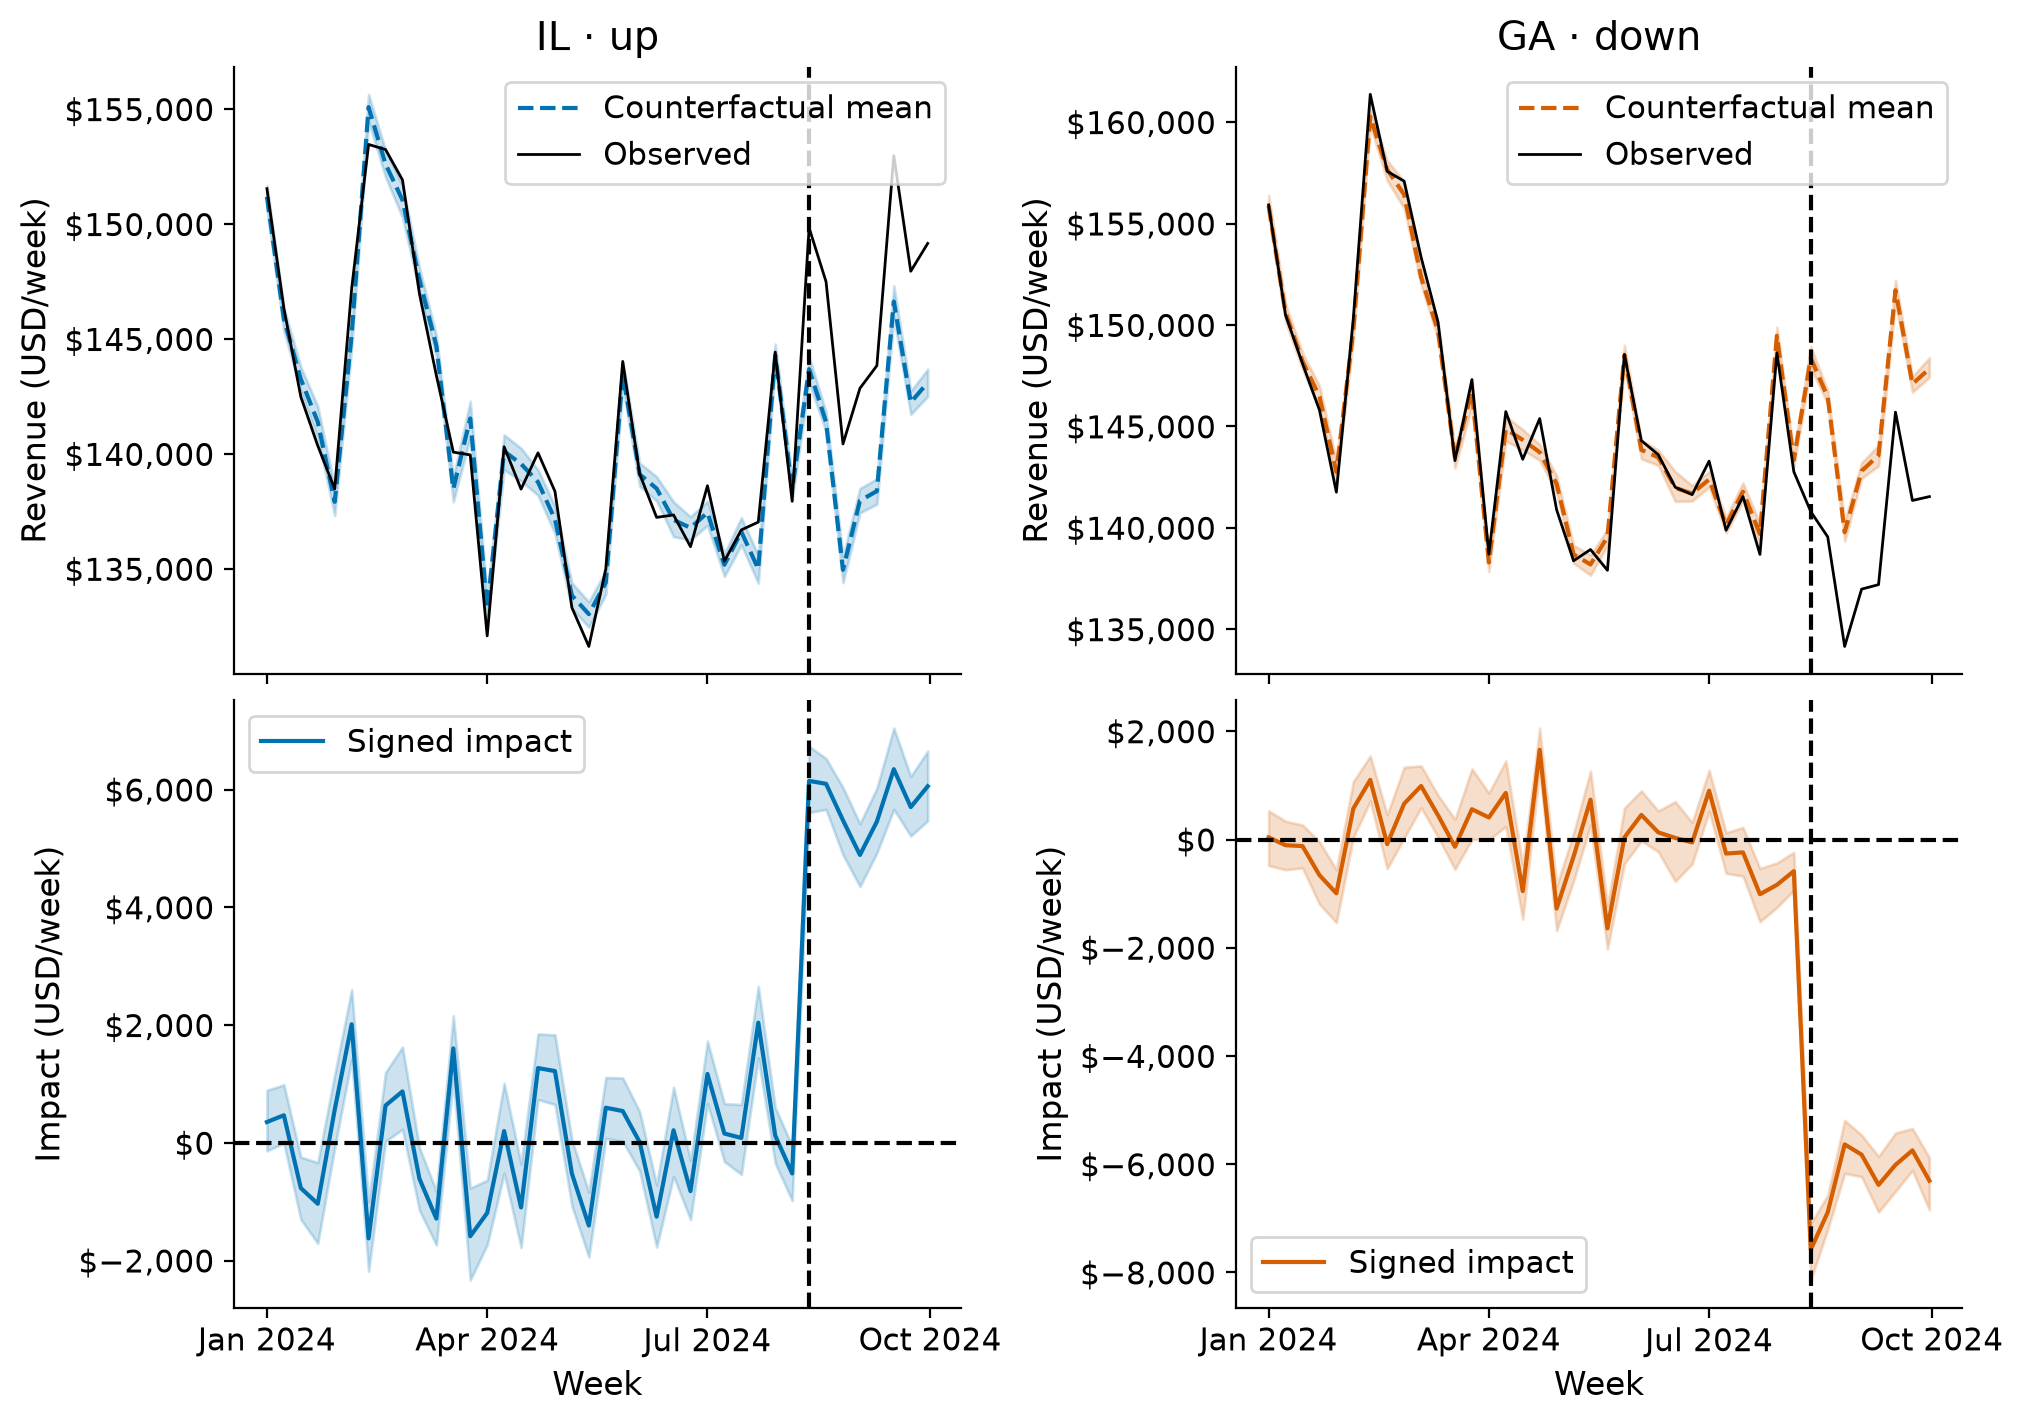

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2), sharex=True)
for col, arm in enumerate(["up", "down"]):
    g = representatives[arm]
    color = ARM_COLORS[arm]
    pre = result.result.impact_pre.sel(treated_units=g)
    post = result.impact_draws.sel(treated_units=g)
    impacts = xr.concat([pre, post], dim="obs_ind").transpose(
        "chain", "draw", "obs_ind"
    )
    observed = experiment_revenue[g]
    cf = (
        xr.DataArray(
            observed.to_numpy(), dims="obs_ind", coords={"obs_ind": observed.index}
        )
        - impacts
    )
    for row, draws, label in [
        (0, cf, "Counterfactual mean"),
        (1, impacts, "Signed impact"),
    ]:
        ax = axes[row, col]
        bounds = draws.quantile([0.03, 0.97], dim=["chain", "draw"])
        ax.fill_between(
            estimation_dates,
            bounds.isel(quantile=0),
            bounds.isel(quantile=1),
            color=color,
            alpha=0.2,
        )
        ax.plot(
            estimation_dates,
            draws.mean(["chain", "draw"]),
            color=color,
            linestyle="--" if row == 0 else "-",
            label=label,
        )
        ax.axvline(experiment_start, color="black", linestyle="--")
        ax.yaxis.set_major_formatter(USD)
        ax.set_ylabel("Revenue (USD/week)" if row == 0 else "Impact (USD/week)")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.legend(fontsize=11)
    axes[0, col].plot(
        estimation_dates, observed, color="black", linewidth=1, label="Observed"
    )
    axes[0, col].set_title(f"{g} · {arm}")
    axes[0, col].legend(fontsize=11)
    axes[1, col].axhline(0, color="black", linestyle="--")
    axes[1, col].set_xlabel("Week")
plt.show()

**Caption:** Observed revenue, synthetic counterfactual, and signed weekly impact for median-baseline-spend up/down geos. Bands are 94% equal-tailed posterior intervals (ETIs); the vertical dashed line marks intervention. These impact intervals condition on observed donor outcomes.

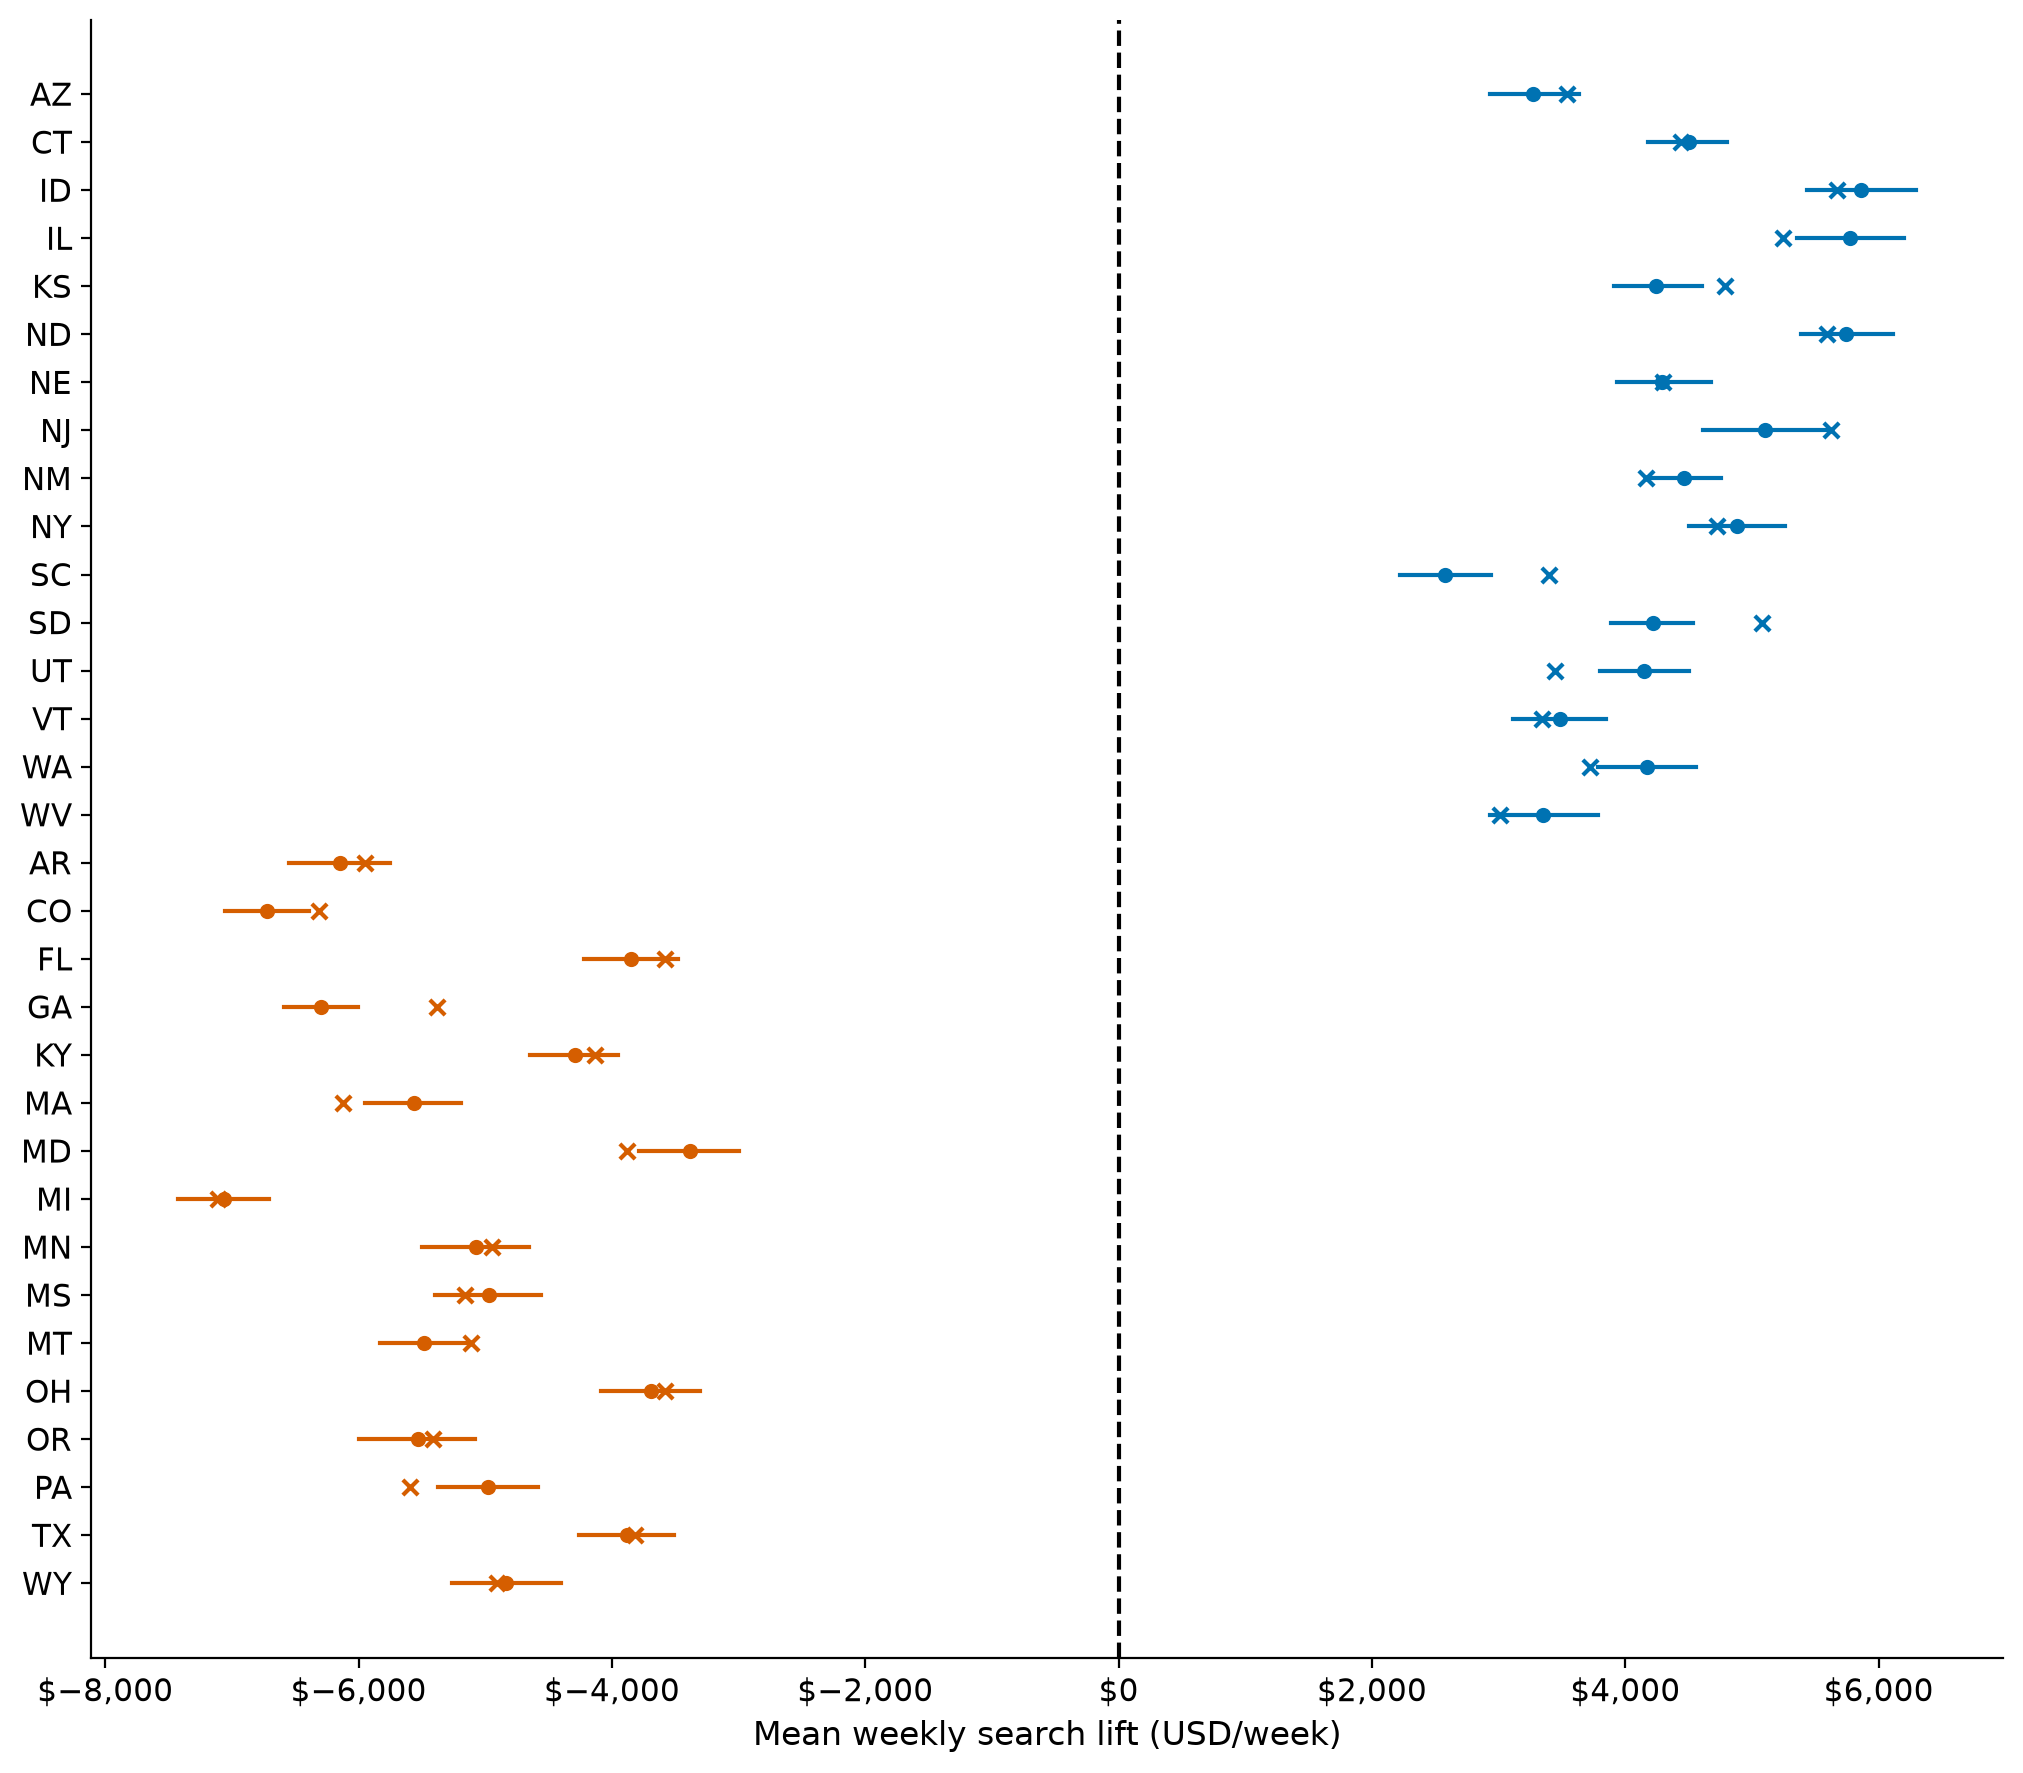

In [13]:
summaries = result.arm_effect_table(
    start=experiment_start, end=experiment_end, aggregate="mean"
)
geo_effects = summaries.query("level == 'geo'").set_index("geo").loc[lift_rows.geo]
geo_effects["truth"] = true_lift.reindex(geo_effects.index)
geo_effects["covered"] = (geo_effects.truth >= geo_effects.lower_94) & (
    geo_effects.truth <= geo_effects.upper_94
)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT * 2.5))
for i, (_g, row) in enumerate(geo_effects.iterrows()):
    color = ARM_COLORS[row.arm]
    ax.plot([row.lower_94, row.upper_94], [i, i], color=color)
    ax.scatter(row["mean"], i, color=color, s=20)
    ax.scatter(row.truth, i, color=color, marker="x", s=30)
ax.set_yticks(range(len(geo_effects)), geo_effects.index)
ax.invert_yaxis()
ax.axvline(0, color="black", linestyle="--")
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Mean weekly search lift (USD/week)")
plt.show()

**Caption:** Estimated mean weekly lift (dots), 94% equal-tailed posterior intervals (segments), and true mean effects (crosses) for all 32 treated markets, ordered by arm. Each interval summarizes one market over the eight intervention weeks; these are the geo-level rows used for calibration.

Comparing intervals with true-effect crosses checks recovery in this simulation. The computed coverage count below is a diagnostic for this one realization, not an estimate of repeated-sampling coverage. It is separate from whether the experiment changes total spend or total revenue.

The stock impact draws condition on observed treated and donor outcomes; they do not represent all repeated-outcome and counterfactual uncertainty. Treat exported SDs and resulting calibration precision as a conditional approximation, not a validated uncertainty model for a real experiment.

In [14]:
print(
    f"True effects inside conditional 94% intervals: {geo_effects.covered.sum()}/{len(geo_effects)}"
)

True effects inside conditional 94% intervals: 19/32


### Does spend neutrality imply revenue neutrality?

The budget accounting showed no net change in search spend. To assess the revenue consequence, sum the geo-level effects within each arm and across both active arms. These are **total effects across markets, in USD/week**, averaged over the same eight weeks. Controls contribute zero intervention effect in this simulation. The summaries below are for interpretation; they are not extra calibration observations.

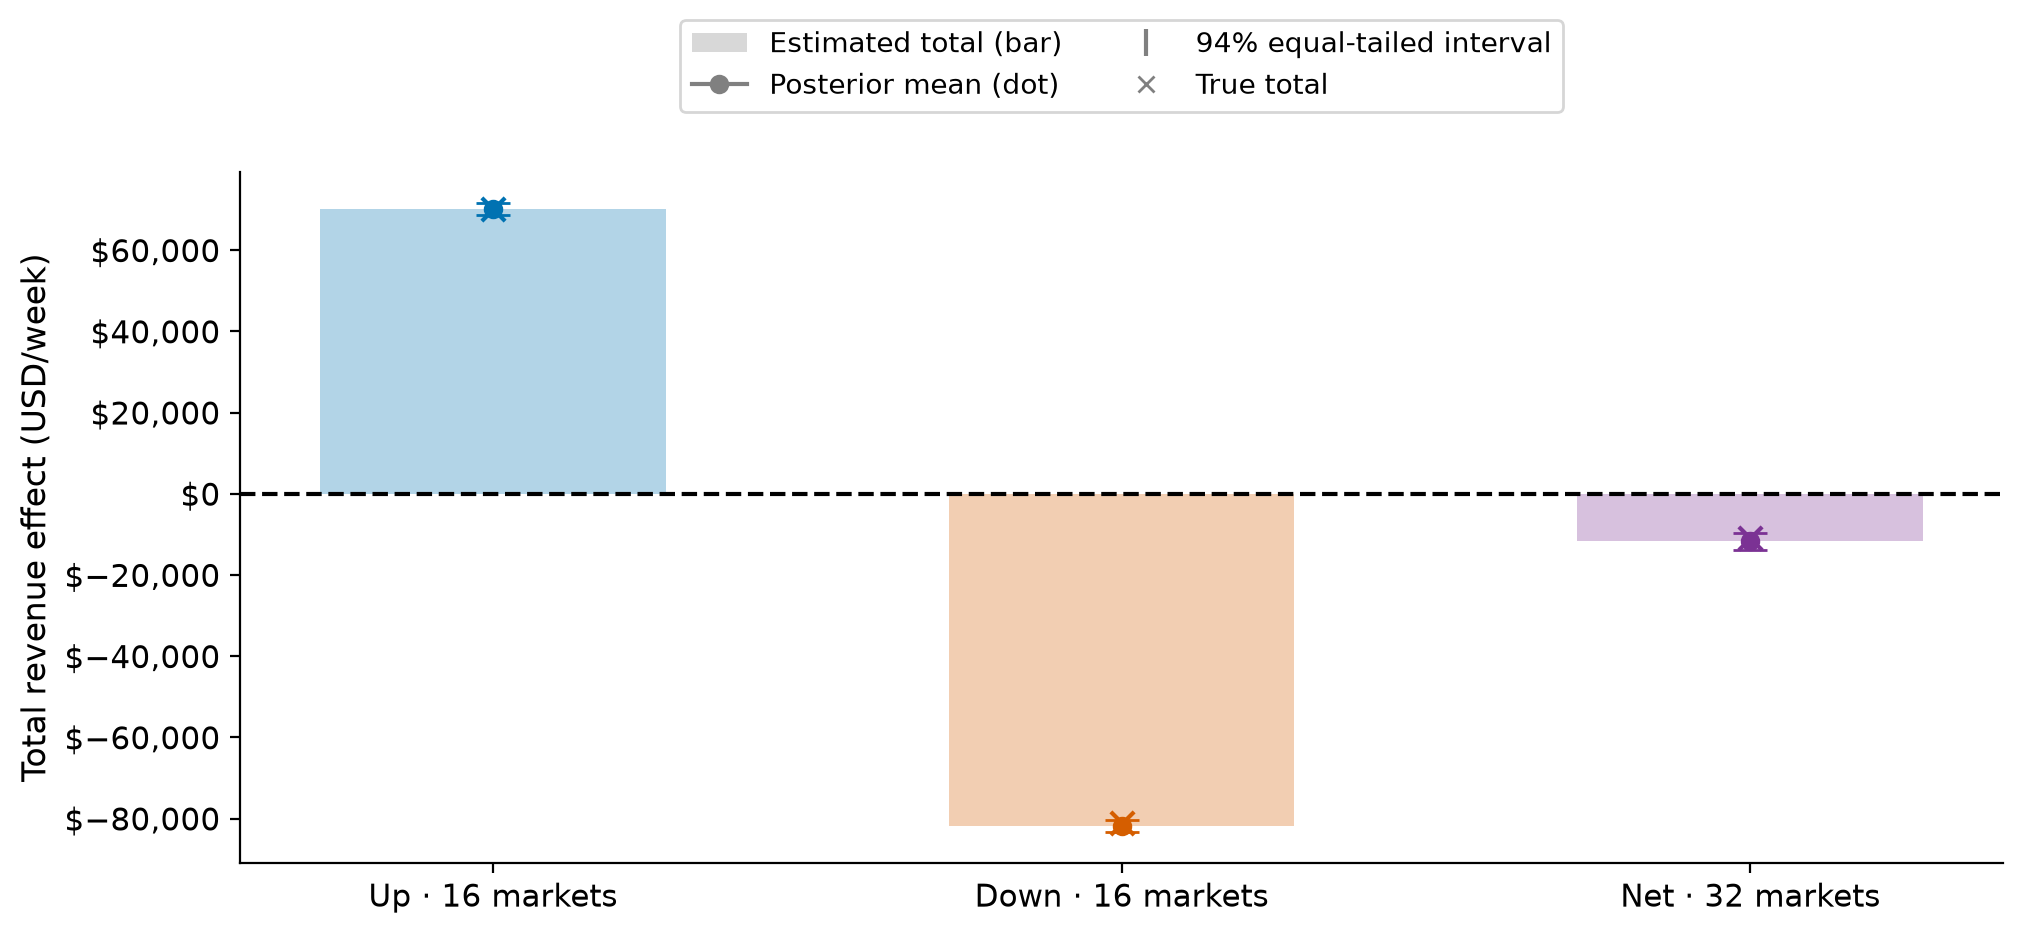

In [15]:
effect_draws = result.aggregate_draws(
    start=experiment_start, end=experiment_end, aggregate="mean"
)["geo"].sel(treated_units=lift_rows.geo.tolist())
# Sum corresponding joint draws, retaining the dependence represented by the fit.
arm_totals = [
    effect_draws.sel(treated_units=arms[arm]).sum("treated_units")
    for arm in ["up", "down"]
]
revenue_totals = xr.concat(
    [*arm_totals, effect_draws.sum("treated_units")],
    dim=pd.Index(["up", "down", "net"], name="summary"),
)
true_totals = [true_lift.loc[arms[arm]].sum() for arm in ["up", "down"]]
true_totals.append(true_lift.loc[arms["up"] + arms["down"]].sum())
means = revenue_totals.mean(["chain", "draw"])
intervals = revenue_totals.quantile([0.03, 0.97], dim=["chain", "draw"])
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT * 1.3))
for i, (label, color, truth) in enumerate(
    zip(
        ["up", "down", "net"],
        [COLOR_UP, COLOR_DOWN, COLOR_NET],
        true_totals,
        strict=True,
    )
):
    mean = float(means.sel(summary=label))
    lower, upper = intervals.sel(summary=label).values
    ax.bar(i, mean, color=color, alpha=0.3, width=0.55)
    ax.errorbar(
        i, mean, yerr=[[mean - lower], [upper - mean]], fmt="o", color=color, capsize=6
    )
    ax.scatter(i, truth, marker="x", color=color, s=70, zorder=4)
ax.legend(
    handles=[
        Patch(facecolor="gray", alpha=0.3, label="Estimated total (bar)"),
        Line2D([], [], marker="o", color="gray", label="Posterior mean (dot)"),
        ax.errorbar(
            [],
            [],
            yerr=[],
            fmt="none",
            color="gray",
            capsize=6,
            label="94% equal-tailed interval",
        ),
        Line2D([], [], marker="x", linestyle="none", color="gray", label="True total"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.24),
    ncol=2,
    fontsize=10,
)
ax.set_xticks(range(3), ["Up · 16 markets", "Down · 16 markets", "Net · 32 markets"])
ax.axhline(0, color="black", linestyle="--")
ax.yaxis.set_major_formatter(USD)
ax.set_ylabel("Total revenue effect (USD/week)")
plt.show()

**Caption:** Posterior mean total weekly revenue effects (bars/dots), 94% equal-tailed intervals (whiskers), and true totals (crosses), for each active arm and their net effect. Totals sum aligned geo-level posterior draws before computing intervals, preserving the dependence available in those draws. Intervals retain the conditional uncertainty limitations described above.

The known response curves produce a negative net revenue effect here, even though delivered spend changes cancel. Cutting search in the down markets loses more revenue than the up markets gain. More deliberate market assignment or dose choices could bring the expected net revenue effect closer to zero, but would require pre-experiment response information and attention to counterfactual fit and statistical power. We do not optimize that allocation in this example.

In [16]:
effect_matrix = (
    effect_draws.stack(sample=("chain", "draw"))
    .transpose("treated_units", "sample")
    .values
)
effect_correlations = np.corrcoef(effect_matrix)
off_diagonal = effect_correlations[np.triu_indices(len(lift_rows), 1)]
effect_skewness = pd.DataFrame(effect_matrix.T).skew()
display(
    pd.Series(
        {
            "Median absolute off-diagonal correlation": np.median(np.abs(off_diagonal)),
            "Maximum absolute off-diagonal correlation": np.max(np.abs(off_diagonal)),
            "Maximum absolute marginal skewness": np.abs(effect_skewness).max(),
        }
    )
)

Median absolute off-diagonal correlation     0.014362
Maximum absolute off-diagonal correlation    0.065305
Maximum absolute marginal skewness           0.145659
dtype: float64

The rowwise likelihood below keeps marginal means and SDs and discards cross-geo covariance and non-Gaussian shape:

$$
\widehat{\Delta y_g}\sim\operatorname{Normal}\!\left(f_g(x_g+\Delta x_g)-f_g(x_g),\sigma_g\right).
$$

This is a **two-stage marginal-summary approximation**, not a full joint causal/MMM likelihood. The stock fit conditions on the observed controls and has geo-specific parameters. Small sampled correlations do not establish independence of real-world uncertainty, including shared donor shocks and counterfactual-model error. Strong dependence or skew calls for investigation before claiming precision; a covariance-aware extension is outside this example.

## Step 2: calibrate a hierarchical geo MMM

The second step models revenue from spend and seasonality across **all 136 pre-intervention weeks**, including the donor-fit weeks. Each geo/channel has its own logistic `lam` and `beta`. We partially pool **amplitudes (`beta`) through channel-level population distributions across all geos**. Curvatures (`lam`) have informative per-geo/channel LogNormal priors with log-scale SD 0.15, centered on channel curvature knowledge. In this simulation their centers match the generating population medians, so both fits receive helpful shape information. We do not fit one model per arm or pool only within arms: arm labels describe the experiment and are provenance metadata, not an MMM dimension.

We fit this same MMM twice, with identical priors, data, scaling, and sampler settings. The **uncalibrated** fit uses the ordinary target likelihood alone. The **calibrated** fit also receives one signed experimental search constraint per treated geo. Both omit latent demand, so the contrast tests whether experimental evidence reduces attribution error under that misspecification. Each treated geo still supplies only one finite difference of its response curve, not full identification of its two saturation parameters.

The curvature priors deliberately regularize a quantity that one lift contrast cannot identify on its own. Full-curve recovery therefore depends on shape knowledge as well as experimental evidence; use more spend levels or other evidence when that knowledge is unavailable. A broader residual-scale prior (15,000 USD/week) accommodates the omitted demand variation. It does not adjust for confounding.

### Define the shared model

Response-parameter tradeoffs can slow MCMC. Both MMMs use [Nutpie low-rank adaptation](https://pymc-devs.github.io/nutpie/sampling-options.html) and 2,000 tuning plus 2,000 retained draws per chain. We set target acceptance to 0.99 to reduce divergent transitions in the confounded example. This adaptation addresses posterior geometry; it cannot repair confounding or identify a response curve on its own. Check diagnostics for both parameters and the response quantities being interpreted.

In [17]:
def make_mmm():
    saturation_priors = {
        "lam": Prior(
            "LogNormal",
            mu=xr.DataArray(
                np.log([4.0, 3.0]), dims="channel", coords={"channel": channels}
            ),
            sigma=0.15,
            dims=("geo", "channel"),
        ),
        "beta": Prior(
            "Normal",
            transform="exp",
            mu=Prior(
                "Normal",
                mu=xr.DataArray(
                    np.log([0.6, 0.5]), dims="channel", coords={"channel": channels}
                ),
                sigma=0.5,
                dims="channel",
            ),
            sigma=Prior("HalfNormal", sigma=0.3, dims="channel"),
            dims=("geo", "channel"),
            centered=False,
        ),
    }
    return MMM(
        date_column="date",
        target_column="revenue",
        channel_columns=channels,
        dims=("geo",),
        control_columns=["annual_sin", "annual_cos"],
        adstock=NoAdstock(l_max=1),
        saturation=LogisticSaturation(priors=saturation_priors),
        scaling=Scaling(
            channel=FixedScaling(dims=(), value=SCALE),
            target=FixedScaling(dims=(), value=SCALE),
        ),
        model_config={
            "intercept": Prior("Normal", mu=0.6, sigma=0.4, dims="geo"),
            "gamma_control": Prior("Normal", mu=0, sigma=0.1, dims="control"),
            "likelihood": Prior(
                "Normal", sigma=Prior("HalfNormal", sigma=0.15, dims="geo")
            ),
        },
    )

In [18]:
# Verify the media response and outcome scales independently of omitted demand.
truth_mmm = make_mmm()
X_baseline = long_features(baseline, estimation_dates, season_controls[104:])
X_realized = long_features(realized, estimation_dates, season_controls[104:])
truth_predictions = []
for features in (X_baseline, X_realized):
    truth_mmm.build_model(features, pd.Series(np.ones(len(features))))
    fixed = pm.do(
        truth_mmm.model,
        {
            "saturation_lam": true_lam,
            "saturation_beta": true_beta,
            "intercept_contribution": true_intercept,
            "gamma_control": true_gamma,
        },
    )
    truth_predictions.append(
        pm.draw(fixed["mu"].transpose("date", "geo"), random_seed=SEED) * SCALE
        + DEMAND_EFFECT * latent_demand[104:, None]
    )
np.testing.assert_allclose(truth_predictions[0], mu_baseline, rtol=1e-10)
np.testing.assert_allclose(truth_predictions[1], mu_experiment, rtol=1e-10)
np.testing.assert_allclose(
    (truth_predictions[1] - truth_predictions[0])[32:].mean(axis=0),
    true_lift,
    atol=1e-8,
)
del truth_mmm
print("Fixed-truth media response plus direct demand reproduces the simulator.")

Fixed-truth media response plus direct demand reproduces the simulator.


The numerical check adds back the **known direct demand term** only to verify the simulated outcome scale and composition. It cancels between factual and counterfactual paths, leaving the true media contrast. Neither fitted MMM receives latent demand, true effects, or intervention outcomes in its ordinary target likelihood.

### Fit the uncalibrated model

This first fit provides the observational baseline against which experimental calibration is compared.

In [19]:
mmm_uncalibrated = make_mmm()
idata_uncalibrated = mmm_uncalibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Output()

/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.


### Fit the calibrated model

Start a fresh model with the same specification, then attach all 32 signed observations before sampling. Supply original USD/week values; `add_lift_test_measurements` performs the scaling.

In [20]:
mmm_calibrated = make_mmm()  # Fresh model with the same priors and training data.
mmm_calibrated.build_model(X_train, y_train)
mmm_calibrated.add_lift_test_measurements(
    lift_rows,
    likelihood=Prior("Normal"),
    name="multi_arm_geo_lift",
)
np.testing.assert_equal(mmm_calibrated.model["multi_arm_geo_lift"].eval().size, 32)
idata_calibrated = mmm_calibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Output()

For the calibrated fit, build once, attach calibration, then fit. Rebuilding after attachment would discard the calibration graph. One signed Normal observation per geo preserves both directions; collapsing active arms into a near-zero row would erase the information. `arm`, window, and unit columns are provenance, while only the geo/channel coordinates index the MMM.

Keep the exported table with its arm, window, and unit metadata alongside any saved model. MMM persistence retains the six columns consumed by the likelihood, so the full exporter table is the provenance record.

In [21]:
def diagnostic_row(label, draws, sample_stats):
    rhat = az.rhat(draws).to_array().values
    ess = az.ess(draws).to_array().values
    return {
        "fit": label,
        "divergences": int(sample_stats.diverging.sum()),
        "max_rhat": float(np.nanmax(rhat)),
        "min_ess": float(np.nanmin(ess)),
    }


diag = [
    diagnostic_row(
        "CausalPy mean effects",
        effect_draws.to_dataset(name="effect"),
        result.model.idata.sample_stats,
    )
]
for label, idata in [
    ("Uncalibrated MMM", idata_uncalibrated),
    ("Calibrated MMM", idata_calibrated),
]:
    diag.append(
        diagnostic_row(
            label,
            xr.Dataset(
                {
                    var: idata.posterior[var]
                    for var in [
                        "saturation_lam",
                        "saturation_beta",
                        "gamma_control",
                        "intercept_contribution",
                    ]
                }
            ),
            idata.sample_stats,
        )
    )
display(
    pd.DataFrame(diag)
    .set_index("fit")
    .style.format({"max_rhat": "{:.4f}", "min_ess": "{:,.0f}"})
)

,divergences,max_rhat,min_ess
fit,,,
CausalPy mean effects,0,1.0048,"1,669"
Uncalibrated MMM,0,1.0052,550
Calibrated MMM,0,1.0027,932


Inspect divergences, R-hat, and effective sample size before interpreting the comparisons. Targets are zero divergences, R-hat ≤ 1.01, and approximately 400 effective draws for central quantities. These diagnostics assess sampling, not the validity of the counterfactual or pooling assumptions.

Individual saturation parameters can mix more slowly than their implied response curves. Inspect both diagnostic tables: longer runs are needed before interpreting individual amplitudes or curvature parameters when their diagnostics miss these targets. The comparisons below concern sampled response curves.

Read the parameter and curve diagnostics together. Any remaining shortfall calls for longer runs before making precise Monte Carlo claims; the comparisons here illustrate the calibration workflow and its limitations.

### Reality check: what changed in causal response estimates?

The MMMs estimate response curves, rather than a standalone experimental lift parameter. We derive each model's **implied lift** by evaluating the same geo's search response at baseline spend $x_g$ and delivered spend $x_g+\Delta x_g$, then subtracting:

$$
\Delta y_g^{(s)} = f_{g,\mathrm{search}}^{(s)}(x_g+\Delta x_g)-f_{g,\mathrm{search}}^{(s)}(x_g).
$$

We repeat this for every posterior draw $s$, giving a distribution of signed mean weekly revenue changes in USD/week. Other channels, baseline revenue, and seasonality are held the same and cancel. With no carryover and constant experiment spend, this is the experiment's mean weekly contrast, not an eight-week total or a prediction of total revenue.

**Uncalibrated** means this contrast uses curves fitted to the historical outcome likelihood alone. **Calibrated** means it uses curves fitted to that same likelihood plus the CausalPy lift constraints. The black CausalPy crosses are the experiment estimates supplied for calibration; the colored plus signs are known simulation truth. Agreement with calibration inputs is expected and is not independent validation.

The calibrated model registers the derived quantity as `multi_arm_geo_lift_model_estimated_lift_original_scale`. The code below evaluates the same contrast for both fits and checks that the calibrated values match that registered quantity.

In [22]:
def posterior_lifts(idata):
    posterior = idata.posterior
    values = []
    for row in lift_rows.itertuples():
        lam = posterior.saturation_lam.sel(geo=row.geo, channel=row.channel)
        beta = posterior.saturation_beta.sel(geo=row.geo, channel=row.channel)
        values.append(
            SCALE
            * beta
            * (
                np.tanh(lam * (row.x + row.delta_x) / SCALE / 2)
                - np.tanh(lam * row.x / SCALE / 2)
            )
        )
    return xr.concat(values, dim=pd.Index(lift_rows.geo, name="lift_geo"))


lifts_uncalibrated = posterior_lifts(idata_uncalibrated)
lifts_calibrated = posterior_lifts(idata_calibrated)
registered_lift = idata_calibrated.posterior[
    "multi_arm_geo_lift_model_estimated_lift_original_scale"
]
np.testing.assert_allclose(
    registered_lift.transpose("chain", "draw", ...).values,
    lifts_calibrated.transpose("chain", "draw", "lift_geo").values,
)

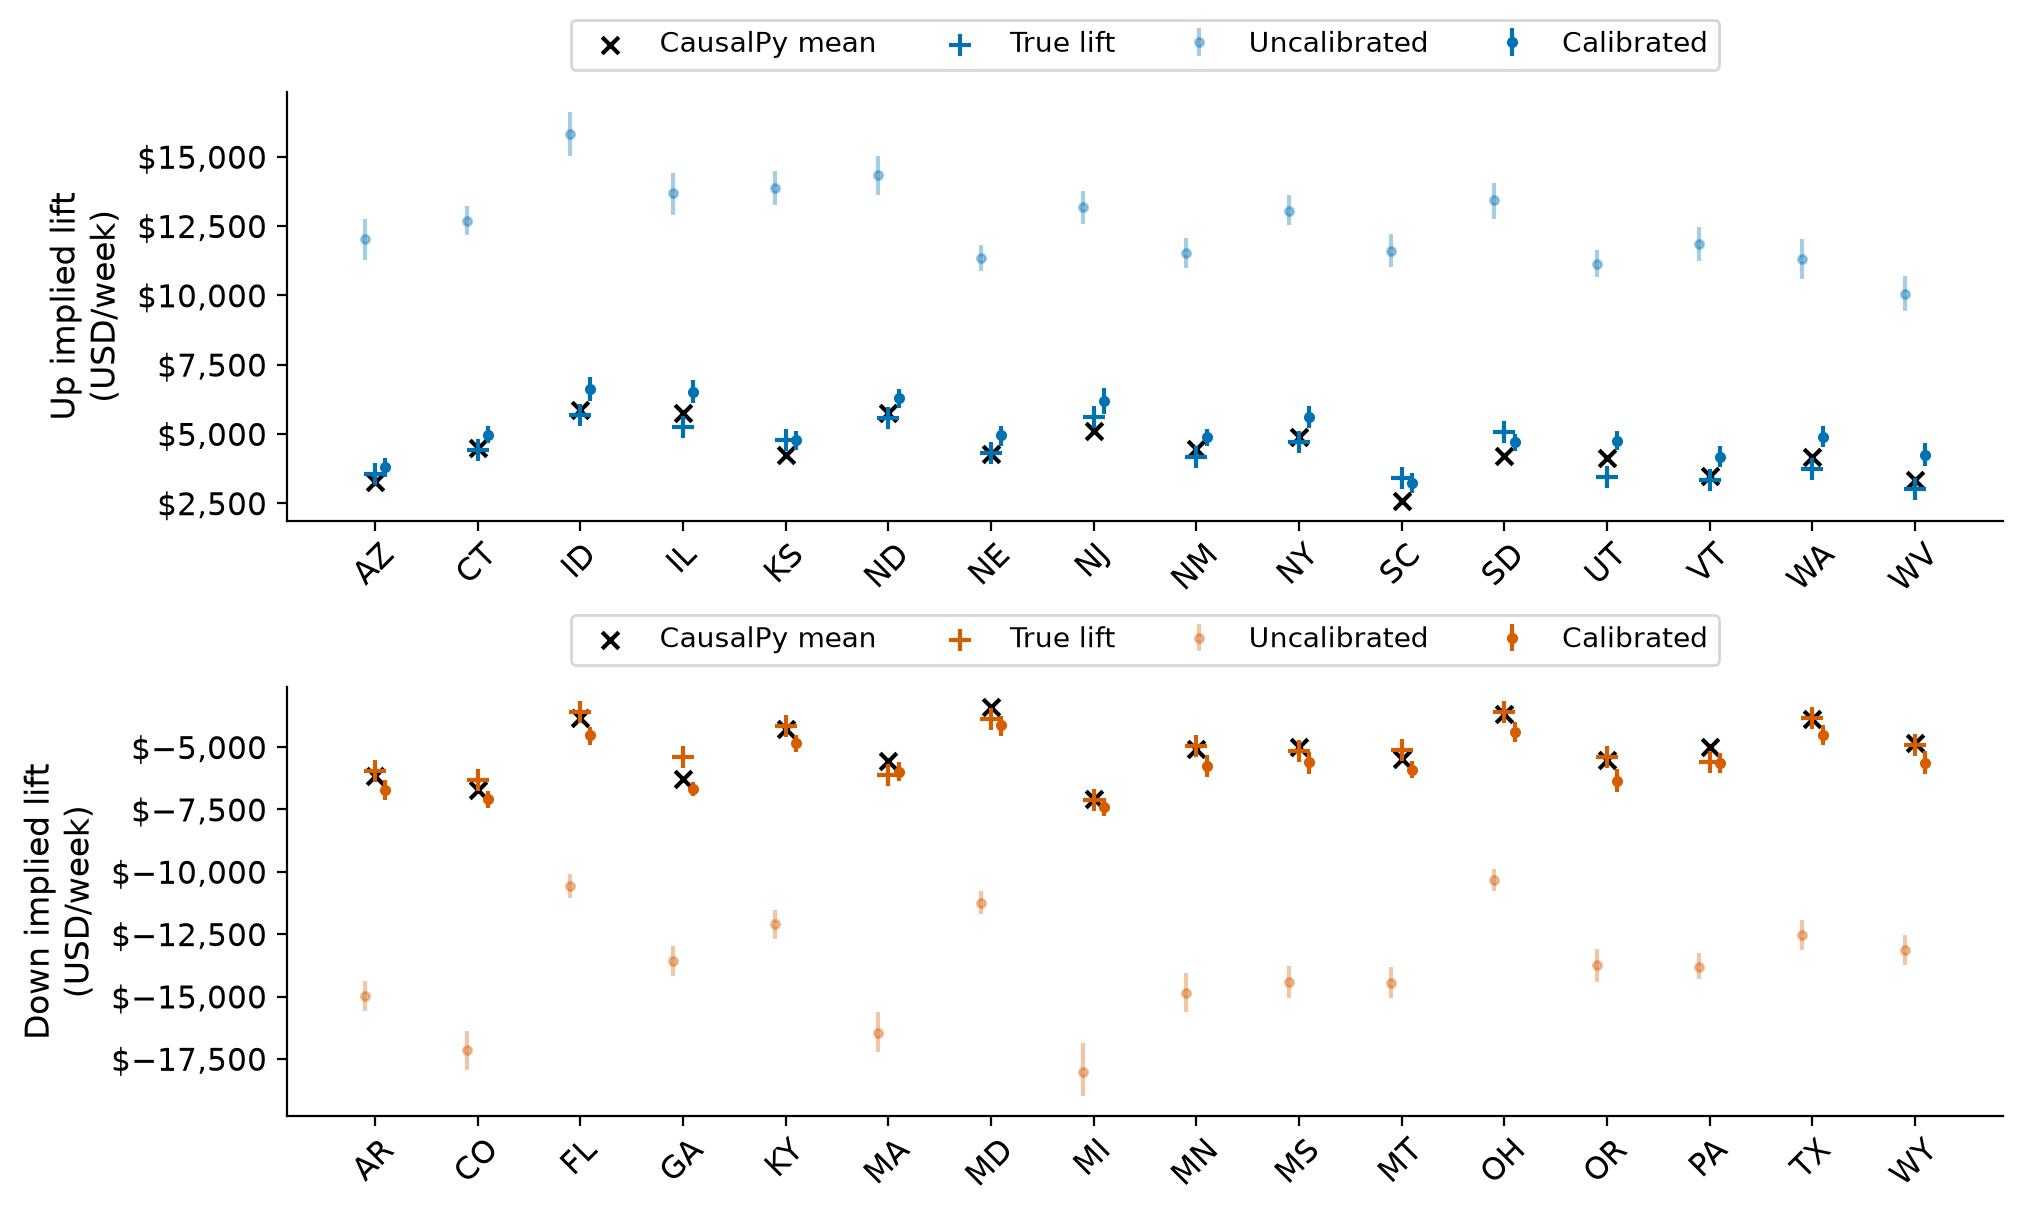

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT * 1.7), sharex=False)
for ax, arm in zip(axes, ["up", "down"], strict=True):
    members = lift_rows.query("arm == @arm")
    positions = np.arange(len(members))
    for j, (draws, label, alpha) in enumerate(
        [
            (lifts_uncalibrated, "Uncalibrated", 0.35),
            (lifts_calibrated, "Calibrated", 1.0),
        ]
    ):
        selected = draws.sel(lift_geo=members.geo.tolist())
        hdi = az.hdi(selected, prob=0.94)
        ax.errorbar(
            positions + (j - 0.5) * 0.2,
            selected.mean(["chain", "draw"]),
            yerr=np.abs(
                hdi.transpose("ci_bound", "lift_geo").values
                - selected.mean(["chain", "draw"]).values
            ),
            fmt="o",
            color=ARM_COLORS[arm],
            alpha=alpha,
            label=label,
            markersize=3,
        )
    ax.scatter(
        positions, members.delta_y, marker="x", color="black", label="CausalPy mean"
    )
    ax.scatter(
        positions,
        true_lift.loc[members.geo],
        marker="+",
        s=65,
        color=ARM_COLORS[arm],
        label="True lift",
        zorder=5,
    )
    ax.set_xticks(positions, members.geo, rotation=45)
    ax.set_ylabel(f"{arm.title()} implied lift\n(USD/week)")
    ax.yaxis.set_major_formatter(USD)
    ax.legend(fontsize=10, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02))
plt.show()

**Caption:** MMM-implied signed mean weekly lifts with 94% HDIs before and after calibration. Black crosses are CausalPy estimates; arm-colored plus signs are known true lifts. Agreement with CausalPy is expected after calibration; comparison with truth evaluates attribution in this simulation.

First inspect the finite contrasts at the spend levels the experiment actually tested. This is the quantity calibration directly constrains. The error summary below compares posterior mean lift with known truth across all treated geos; it does not use agreement with calibration inputs as validation.

In [24]:
lift_recovery = pd.DataFrame(
    [
        {
            "model": label,
            "Mean absolute lift error (USD/week)": float(
                np.abs(
                    draws.mean(["chain", "draw"])
                    - xr.DataArray(
                        true_lift.loc[lift_rows.geo].to_numpy(),
                        dims="lift_geo",
                        coords={"lift_geo": lift_rows.geo.to_numpy()},
                    )
                ).mean()
            ),
            "Lift max R-hat": float(az.rhat(draws).max()),
            "Lift min ESS": float(az.ess(draws).min()),
        }
        for label, draws in [
            ("Uncalibrated", lifts_uncalibrated),
            ("Calibrated", lifts_calibrated),
        ]
    ]
).set_index("model")
display(
    lift_recovery.round(
        {
            "Mean absolute lift error (USD/week)": 1,
            "Lift max R-hat": 4,
            "Lift min ESS": 0,
        }
    )
)

,Mean absolute lift error (USD/week),Lift max R-hat,Lift min ESS
model,,,
Uncalibrated,8470.8,1.0024,1136.0
Calibrated,688.7,1.0025,3482.0


The table shows a large reduction in causal lift error at the tested doses in this realization and reports diagnostics for those posterior contrasts. Apply the same R-hat and ESS targets used above before interpreting small error differences. Next inspect full curves for predetermined representative markets; matching one local contrast need not determine a curve far from the tested spend.

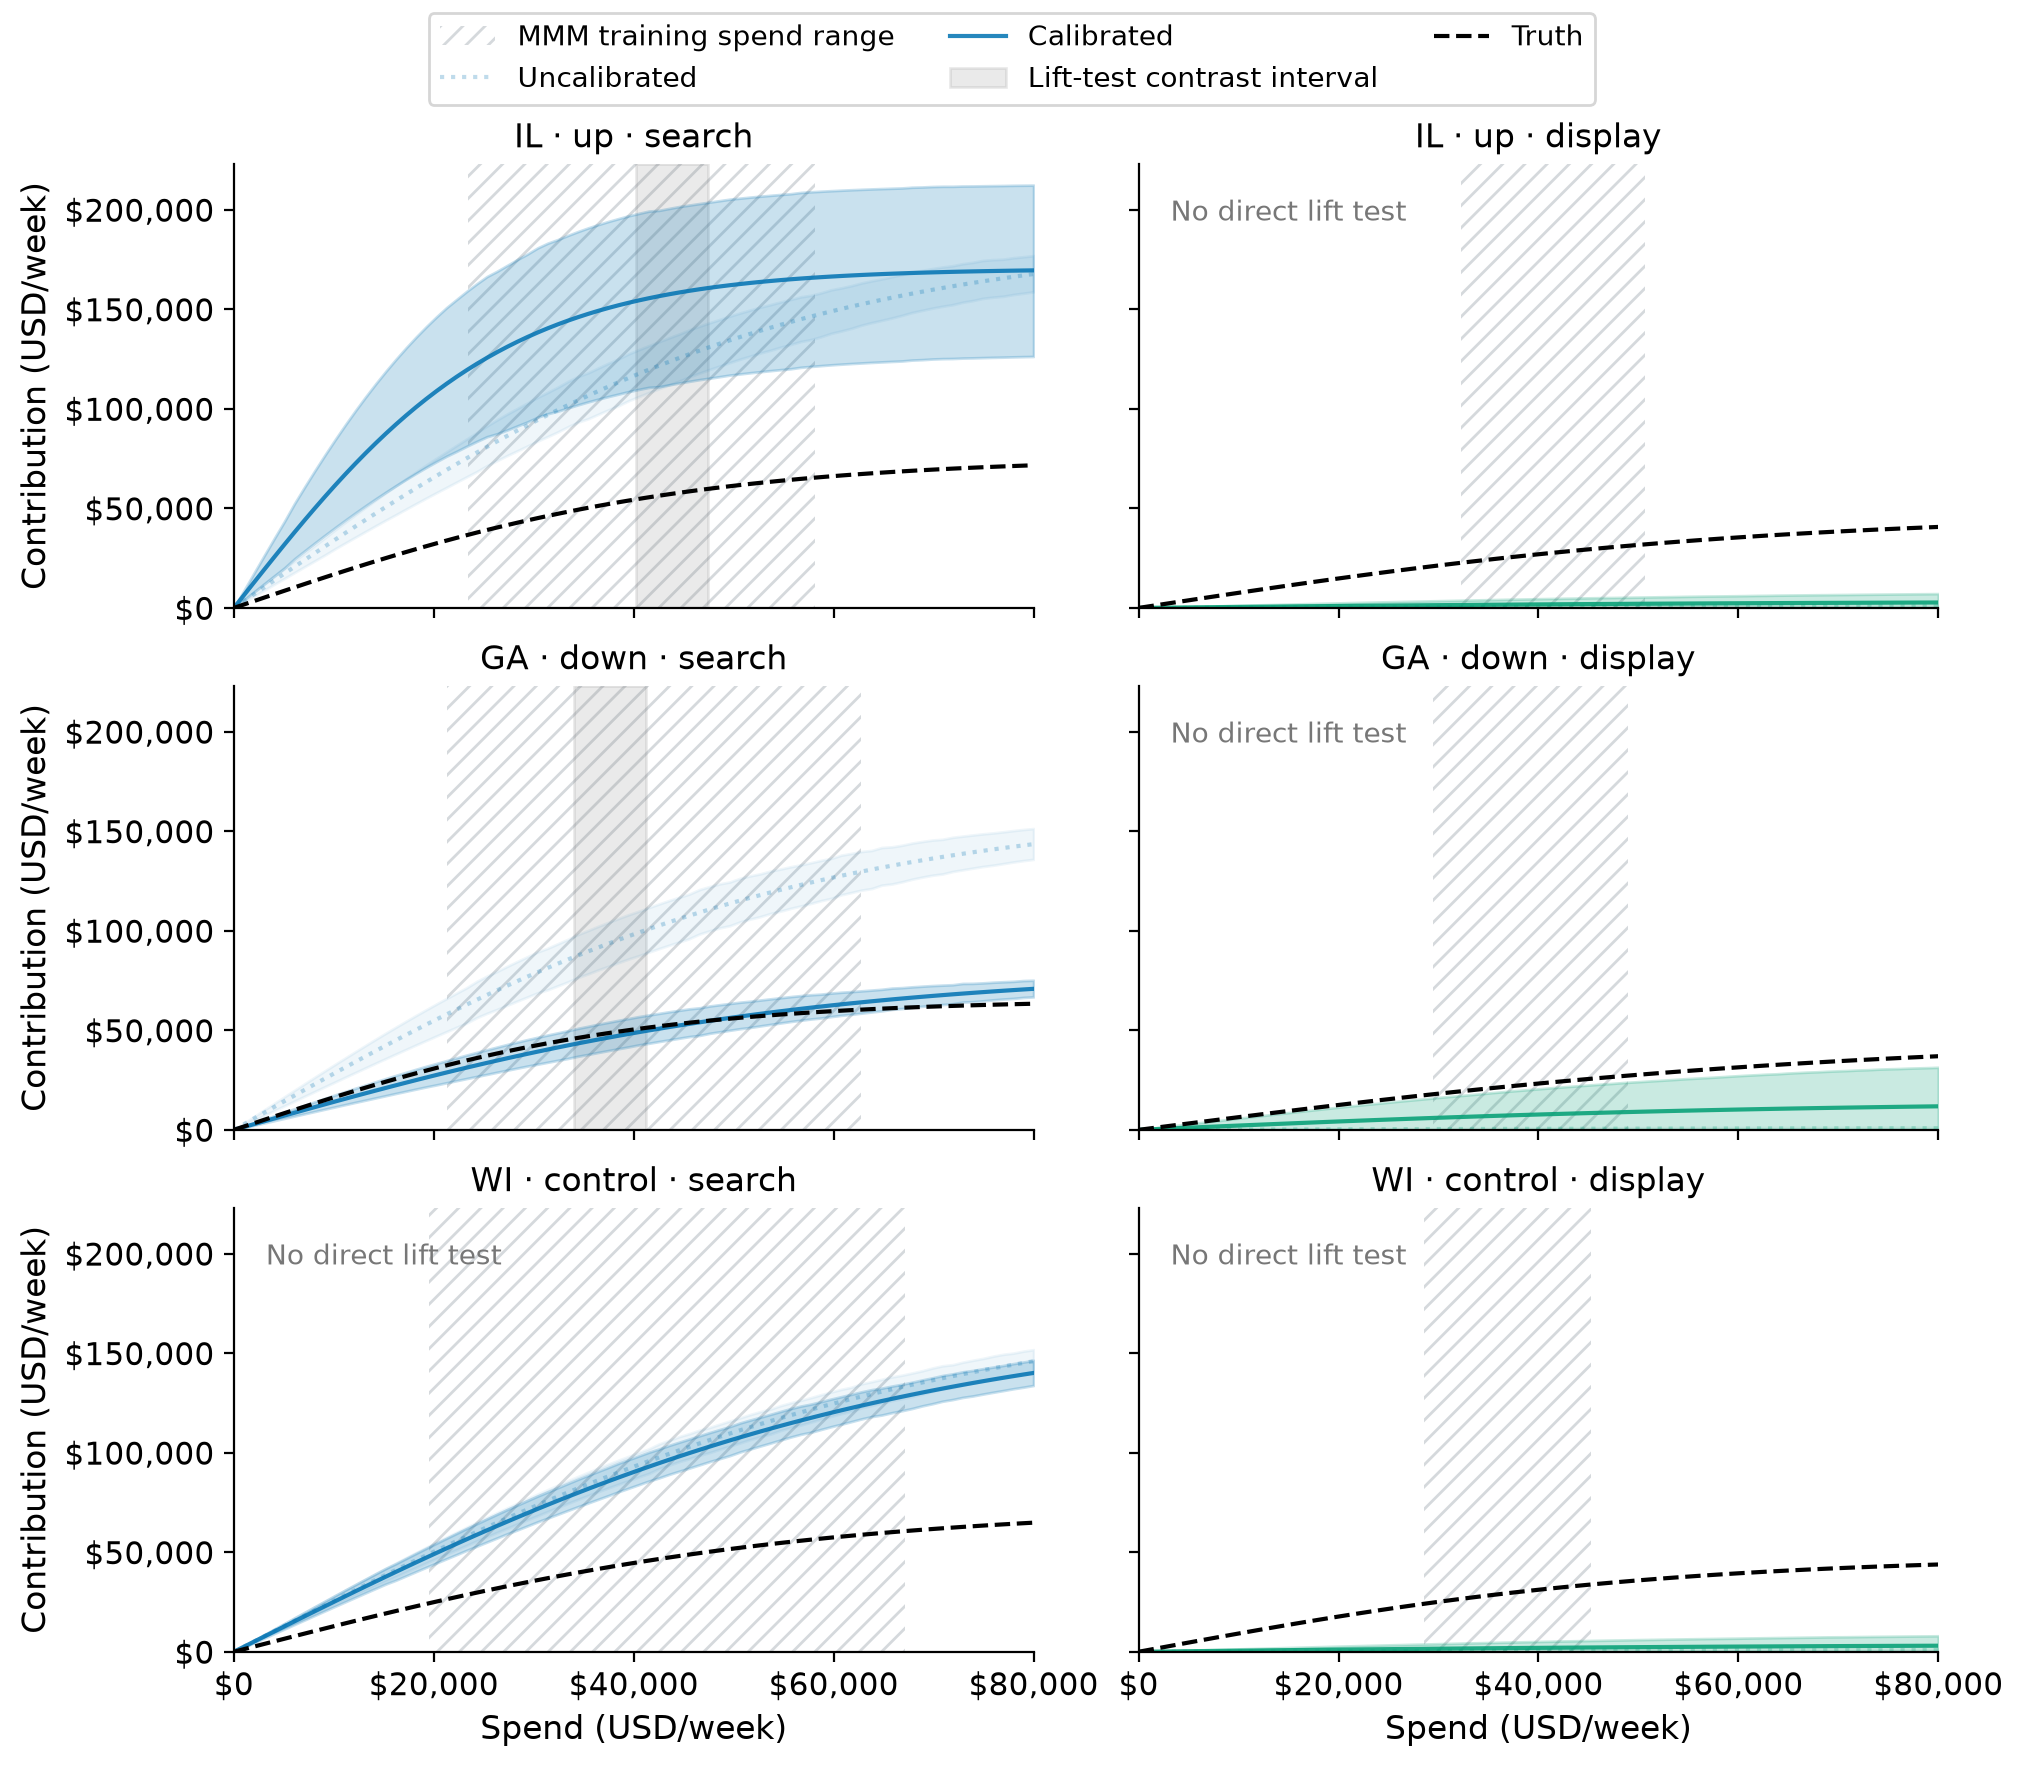

In [25]:
spend_grid = np.linspace(0, 80_000, 80)


def response_draws(idata):
    p = idata.posterior
    spend = xr.DataArray(spend_grid / SCALE, dims="spend", coords={"spend": spend_grid})
    return SCALE * p.saturation_beta * np.tanh(p.saturation_lam * spend / 2)


curve_draws = {
    "Uncalibrated": response_draws(idata_uncalibrated),
    "Calibrated": response_draws(idata_calibrated),
}
posterior_upper = max(
    float(
        az.hdi(draws.sel(geo=list(representatives.values())), prob=0.94)
        .sel(ci_bound="upper")
        .max()
    )
    for draws in curve_draws.values()
)
truth_upper = SCALE * true_beta[[geos.index(g) for g in representatives.values()]].max()
curve_upper = 1.05 * max(posterior_upper, truth_upper)
fig, axes = plt.subplots(
    3, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2.5), sharex=True, sharey=True
)
for row, arm in enumerate(["up", "down", "control"]):
    g = representatives[arm]
    for col, channel in enumerate(channels):
        ax = axes[row, col]
        training_values = X_train.loc[X_train.geo == g, channel]
        ax.axvspan(
            training_values.min(),
            training_values.max(),
            facecolor="none",
            edgecolor=COLOR_DONOR,
            hatch="///",
            linewidth=0,
            alpha=0.35,
            zorder=0,
            label="MMM training spend range",
        )
        for label, alpha, style in [
            ("Uncalibrated", 0.25, ":"),
            ("Calibrated", 0.85, "-"),
        ]:
            draws = curve_draws[label].sel(geo=g, channel=channel)
            hdi = az.hdi(draws, prob=0.94)
            ax.fill_between(
                spend_grid,
                hdi.sel(ci_bound="lower"),
                hdi.sel(ci_bound="upper"),
                color=CHANNEL_COLORS[channel],
                alpha=alpha * 0.25,
            )
            ax.plot(
                spend_grid,
                draws.mean(["chain", "draw"]),
                color=CHANNEL_COLORS[channel],
                alpha=alpha,
                linestyle=style,
                label=label,
            )
        if channel == "search" and arm in ["up", "down"]:
            dose = lift_rows.set_index("geo").loc[g]
            ax.axvspan(
                min(dose.x, dose.x + dose.delta_x),
                max(dose.x, dose.x + dose.delta_x),
                color=COLOR_CONTROL,
                alpha=0.15,
                zorder=0,
                label="Lift-test contrast interval",
            )
        else:
            ax.text(
                0.04,
                0.92,
                "No direct lift test",
                transform=ax.transAxes,
                color=COLOR_CONTROL,
                fontsize=10,
                va="top",
            )
        i, c = geos.index(g), channels.index(channel)
        truth = (
            SCALE * true_beta[i, c] * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
        )
        ax.plot(spend_grid, truth, color="black", linestyle="--", label="Truth")
        ax.set_title(f"{g} · {arm} · {channel}", fontsize=12)
        ax.xaxis.set_major_formatter(USD)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_formatter(USD)
        ax.set(xlim=(0, 80_000), ylim=(0, curve_upper))
        if col == 0:
            ax.set_ylabel("Contribution (USD/week)")
        if row == 2:
            ax.set_xlabel("Spend (USD/week)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, fontsize=10)
plt.show()

**Caption:** Posterior mean channel contributions and 94% HDI bands for predetermined up, down, and control representatives. Dotted/light curves are uncalibrated, solid/dark curves calibrated, and black dashed curves known truth. Hatched spans mark each geo/channel's min–max spend across all MMM training weeks. Solid gray spans join baseline and delivered search spend in treated geos, the two levels defining each lift-test contrast.

The gray spans appear only in the **up/search and down/search panels** because those are the only representative geo/channel pairs with a direct lift observation. Display spend and control-market spend were not manipulated; those panels say "No direct lift test." The hatched historical spend ranges are a separate reference and appear in every panel. The experiment tests a difference between two spend levels, not the entire continuum inside the gray span.

The experiment constrains the **difference** $f_g(x_g+\Delta x_g)-f_g(x_g)$, not the absolute contribution $f_g(x_g)$. Curves can agree on that local difference while remaining vertically far apart over the tested interval. Display and control markets have no direct experimental constraint; their contribution estimates can move as the misspecified MMM redistributes revenue.

In [26]:
metric_rows = []
for label, draws in curve_draws.items():
    hdi = az.hdi(draws, prob=0.94)
    for g in geos:
        i = geos.index(g)
        for channel in channels:
            c = channels.index(channel)
            selected = draws.sel(geo=g, channel=channel)
            truth = (
                SCALE
                * true_beta[i, c]
                * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
            )
            bounds = hdi.sel(geo=g, channel=channel)
            metric_rows.append(
                {
                    "model": label,
                    "arm": geo_arm[g],
                    "channel": channel,
                    "MAE (USD/week)": float(
                        np.abs(selected.mean(["chain", "draw"]) - truth).mean()
                    ),
                    "HDI width (USD/week)": float(
                        (
                            bounds.sel(ci_bound="upper") - bounds.sel(ci_bound="lower")
                        ).mean()
                    ),
                    "Truth coverage": float(
                        (
                            (truth >= bounds.sel(ci_bound="lower"))
                            & (truth <= bounds.sel(ci_bound="upper"))
                        ).mean()
                    ),
                }
            )
curve_metrics = pd.DataFrame(metric_rows).groupby(["channel", "arm", "model"]).mean()
display(curve_metrics.round(2))

MAE (USD/week)  HDI width (USD/week)  \
channel arm     model                                                
display control Calibrated          23860.18               4545.51   
                Uncalibrated        25137.78                569.96   
        down    Calibrated          16535.88              34576.45   
                Uncalibrated        23924.83                570.68   
        up      Calibrated          15605.17              19621.73   
                Uncalibrated        23969.91                566.06   
search  control Calibrated          48142.61              13799.18   
                Uncalibrated        51167.10              12537.58   
        down    Calibrated           3643.67              10776.22   
                Uncalibrated        50835.07              13292.26   
        up      Calibrated          64999.06              62897.12   
                Uncalibrated        53331.06              13500.26   

                              Truth coverage  
channel arm     model                         
display control Calibrated              0.01  
                Uncalibrated            0.01  
        down    Calibrated              0.54  
                Uncalibrated            0.01  
        up      Calibrated              0.38  
                Uncalibrated            0.01  
search  control Calibrated              0.01  
                Uncalibrated            0.01  
        down    Calibrated              0.75  
                Uncalibrated            0.01  
        up      Calibrated              0.03  
                Uncalibrated            0.01

Curve error and interval width are averaged over the displayed 0–80,000 USD/week grid, then across geos within each arm. Coverage is the fraction of grid points whose truth lies in the pointwise 94% HDI. These summaries include extrapolation beyond observed spend; they are not forecast scores or population bias estimates. Search is directly calibrated, while display and controls change only through the shared model and parameter tradeoffs.

In this run, search curve error improves for the down arm but worsens for the up arm, while control search remains biased. This is compatible with the much better tested-lift estimates: the local differences improve even when absolute contribution levels do not. Calibration can reduce bias in the tested search contrast without recovering the entire response curve or correcting omitted demand everywhere. Narrower conditional intervals alone do not demonstrate better recovery. The next table checks Monte Carlo diagnostics for central curve points before interpreting small differences in these summaries.

In [27]:
curve_diagnostics = []
for label, draws in curve_draws.items():
    central_curves = draws.sel(spend=spend_grid[[20, 40, 60]])
    curve_diagnostics.append(
        {
            "model": label,
            "curve max R-hat": float(az.rhat(central_curves).max()),
            "curve min ESS": float(az.ess(central_curves).min()),
        }
    )
display(pd.DataFrame(curve_diagnostics).round(4))
print(f"Total elapsed: {(time.perf_counter() - started) / 60:.1f} minutes")

,model,curve max R-hat,curve min ESS
0,Uncalibrated,1.0048,1855.1906
1,Calibrated,1.0036,970.4821


Total elapsed: 14.6 minutes


Compare curve R-hat and ESS with the targets above. Any shortfall limits precise Monte Carlo claims even when the point estimates move toward truth.

### Local returns: experimental average slope and marginal ROAS

A lift test tells us most directly about the **average slope over its spend change**:

$$
r_g = \frac{f_g(x_g+\Delta x_g)-f_g(x_g)}{\Delta x_g}
    = \frac{1}{\Delta x_g}\int_{x_g}^{x_g+\Delta x_g} f'_g(u)\,du.
$$

This is incremental revenue per incremental dollar of search spend. In a down arm, both lift and spend change are negative, so the ratio is positive: revenue lost per dollar cut. It is not total attributed revenue divided by total spend.

**Marginal ROAS** is the derivative at a particular operating spend. For this notebook's logistic curve, in original USD units,

$$
\operatorname{mROAS}_g(x)=f'_g(x)
=\frac{\beta_g\lambda_g}{2}\left[1-\tanh^2\!\left(\frac{\lambda_gx}{2S}\right)\right],
\qquad S=100{,}000.
$$

For a small spend change, the interval average approaches marginal ROAS. For a finite change they need not coincide: on these concave curves, the up-test average slope is below the slope at baseline, while the down-test average is above it. Calibration directly constrains the interval average; the derivative at baseline still depends on curvature, priors, and pooling. Here both ratios describe contemporaneous revenue per spend dollar, since the simulator has no carryover.

We compute both quantities for each posterior draw at the same 32 tested geo-specific spend points. The derivative function also supports the local curve plots below.

In [28]:
def marginal_roas(lam, beta, spend):
    return beta * lam / 2 * (1 - np.tanh(lam * spend / (2 * SCALE)) ** 2)


lift_geo = xr.DataArray(
    lift_rows.geo.to_numpy(),
    dims="lift_geo",
    coords={"lift_geo": lift_rows.geo.to_numpy()},
)
baseline_spend = xr.DataArray(
    lift_rows.x.to_numpy(), dims="lift_geo", coords=lift_geo.coords
)
spend_change = xr.DataArray(
    lift_rows.delta_x.to_numpy(), dims="lift_geo", coords=lift_geo.coords
)
local_returns = {}
for label, idata, lifts in [
    ("Uncalibrated", idata_uncalibrated, lifts_uncalibrated),
    ("Calibrated", idata_calibrated, lifts_calibrated),
]:
    p = idata.posterior.sel(geo=lift_geo, channel="search")
    local_returns[label] = xr.Dataset(
        {
            "interval_average": lifts / spend_change,
            "marginal_at_baseline": marginal_roas(
                p.saturation_lam, p.saturation_beta, baseline_spend
            ),
        }
    )

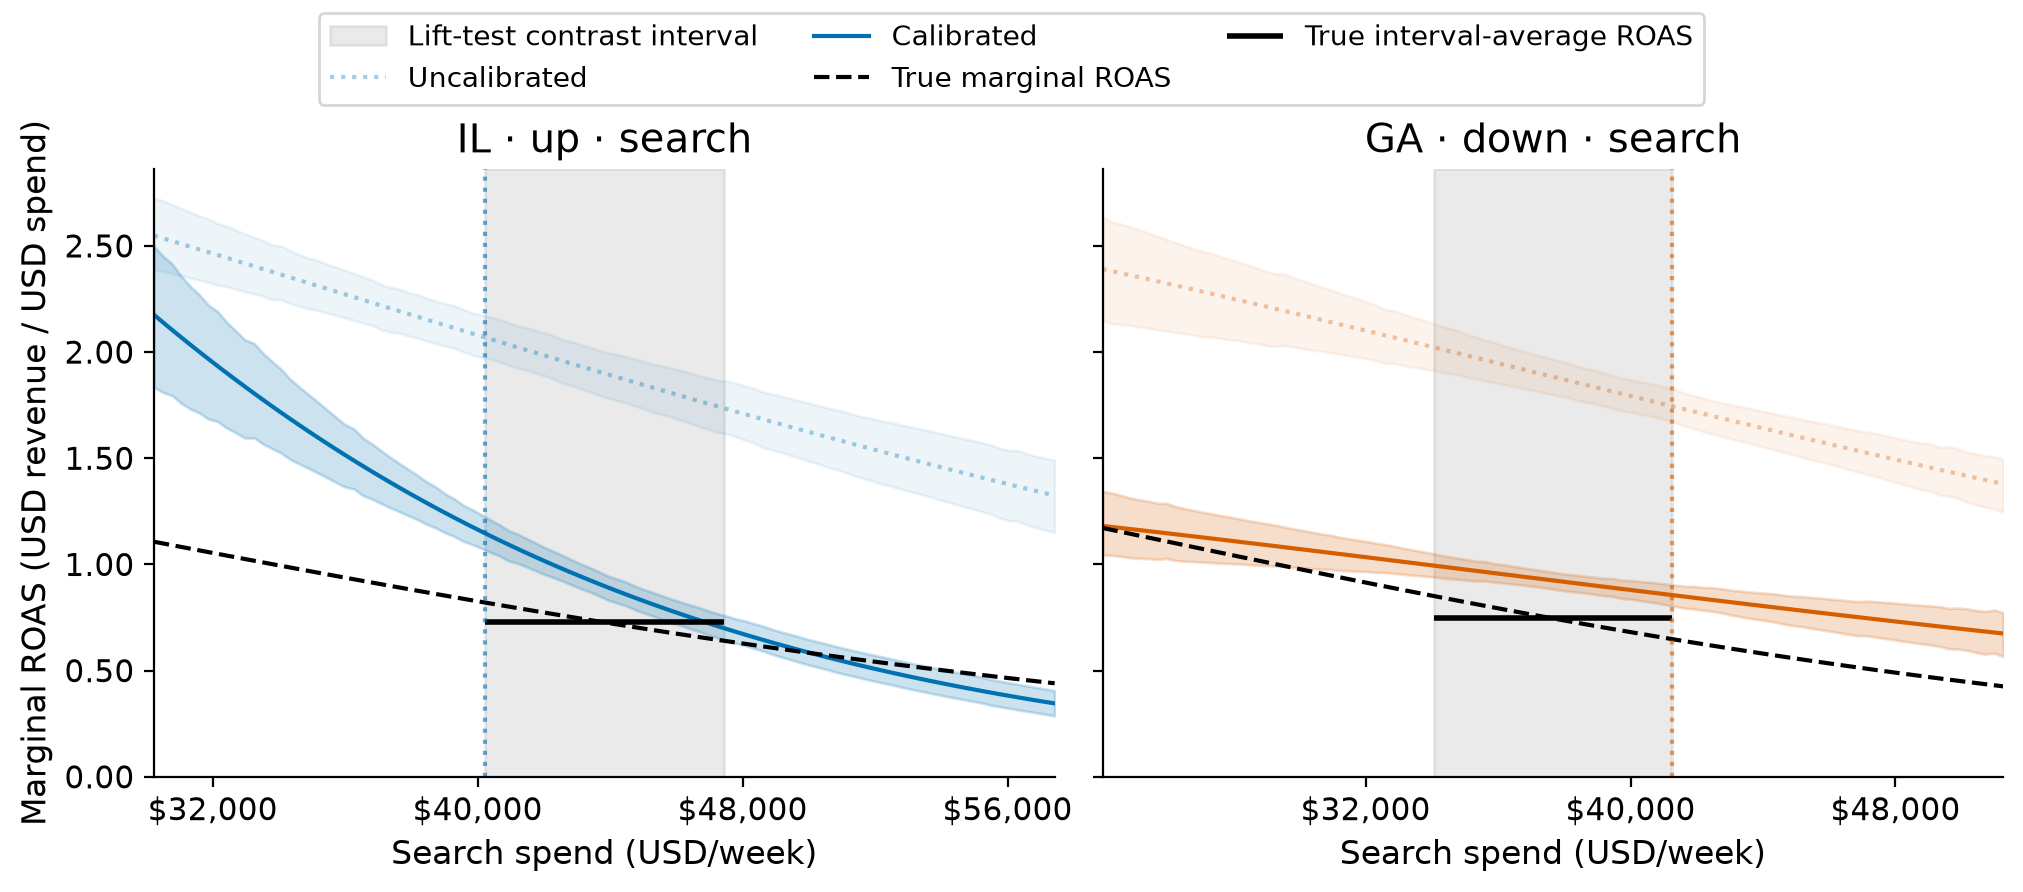

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 1.25), sharey=True)
local_upper = 0.0
for ax, arm in zip(axes, ["up", "down"], strict=True):
    g = representatives[arm]
    dose = lift_rows.set_index("geo").loc[g]
    lower, upper = sorted([dose.x, dose.x + dose.delta_x])
    local_spend = np.linspace(max(0, lower - 10_000), upper + 10_000, 100)
    spend = xr.DataArray(local_spend, dims="spend")
    ax.axvspan(
        lower,
        upper,
        color=COLOR_CONTROL,
        alpha=0.15,
        label="Lift-test contrast interval",
    )
    for label, idata, alpha, style in [
        ("Uncalibrated", idata_uncalibrated, 0.35, ":"),
        ("Calibrated", idata_calibrated, 1.0, "-"),
    ]:
        p = idata.posterior.sel(geo=g, channel="search")
        draws = marginal_roas(p.saturation_lam, p.saturation_beta, spend)
        hdi = az.hdi(draws, prob=0.94)
        ax.fill_between(
            local_spend,
            hdi.sel(ci_bound="lower"),
            hdi.sel(ci_bound="upper"),
            color=ARM_COLORS[arm],
            alpha=alpha * 0.2,
        )
        ax.plot(
            local_spend,
            draws.mean(["chain", "draw"]),
            color=ARM_COLORS[arm],
            alpha=alpha,
            linestyle=style,
            label=label,
        )
        local_upper = max(local_upper, float(hdi.sel(ci_bound="upper").max()))
    i = geos.index(g)
    truth = marginal_roas(true_lam[i, 0], true_beta[i, 0], local_spend)
    ax.plot(
        local_spend, truth, color="black", linestyle="--", label="True marginal ROAS"
    )
    ax.hlines(
        true_lift[g] / dose.delta_x,
        lower,
        upper,
        color="black",
        linewidth=2,
        label="True interval-average ROAS",
    )
    local_upper = max(local_upper, float(truth.max()))
    ax.axvline(dose.x, color=ARM_COLORS[arm], linestyle=":", alpha=0.6)
    ax.set_title(f"{g} · {arm} · search")
    ax.set_xlabel("Search spend (USD/week)")
    ax.set_xlim(local_spend[0], local_spend[-1])
    ax.xaxis.set_major_formatter(USD)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.2f}"))
axes[0].set_ylabel("Marginal ROAS (USD revenue / USD spend)")
axes[0].set_ylim(0, local_upper * 1.05)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, fontsize=10)
plt.show()

**Caption:** Local search marginal ROAS curves for the predetermined up/down representatives. Lines are posterior means and bands are pointwise 94% HDIs; light/dotted is uncalibrated and dark/solid calibrated. Black dashed curves are true derivatives. The black horizontal segment gives the true average slope over the gray lift-test contrast interval; the arm-colored vertical dotted line marks baseline spend. The horizontal segment represents an interval average, not a derivative at every point.

The experiment constrains an average slope inside the gray interval. The derivative's variation across that interval is supplied by the response-curve shape; moving away from the tested spend pair relies increasingly on other model information. The table below checks both return quantities against truth across all treated geos, not just these representatives.

In [30]:
geo_indices = [geos.index(g) for g in lift_rows.geo]
true_returns = xr.Dataset(
    {
        "interval_average": xr.DataArray(
            true_lift.loc[lift_rows.geo].to_numpy(),
            dims="lift_geo",
            coords=lift_geo.coords,
        )
        / spend_change,
        "marginal_at_baseline": marginal_roas(
            xr.DataArray(
                true_lam[geo_indices, 0], dims="lift_geo", coords=lift_geo.coords
            ),
            xr.DataArray(
                true_beta[geo_indices, 0], dims="lift_geo", coords=lift_geo.coords
            ),
            baseline_spend,
        ),
    }
)
return_metrics = []
return_labels = {
    "interval_average": "Average over test interval",
    "marginal_at_baseline": "Marginal at baseline spend",
}
for quantity, description in return_labels.items():
    for label, draws in local_returns.items():
        selected = draws[quantity]
        hdi = az.hdi(selected, prob=0.94)
        return_metrics.append(
            {
                "Quantity": description,
                "Model": label,
                "MAE (USD/USD)": float(
                    np.abs(
                        selected.mean(["chain", "draw"]) - true_returns[quantity]
                    ).mean()
                ),
                "Mean HDI width (USD/USD)": float(
                    (hdi.sel(ci_bound="upper") - hdi.sel(ci_bound="lower")).mean()
                ),
                "Max R-hat": float(az.rhat(selected).max()),
                "Min ESS": float(az.ess(selected).min()),
            }
        )
display(pd.DataFrame(return_metrics).set_index(["Quantity", "Model"]).round(3))

MAE (USD/USD)  \
Quantity                   Model                         
Average over test interval Uncalibrated          1.176   
                           Calibrated            0.096   
Marginal at baseline spend Uncalibrated          1.180   
                           Calibrated            0.159   

                                         Mean HDI width (USD/USD)  Max R-hat  \
Quantity                   Model                                               
Average over test interval Uncalibrated                     0.175      1.002   
                           Calibrated                       0.105      1.002   
Marginal at baseline spend Uncalibrated                     0.160      1.004   
                           Calibrated                       0.128      1.003   

                                          Min ESS  
Quantity                   Model                   
Average over test interval Uncalibrated  1135.924  
                           Calibrated    3482.398  
Marginal at baseline spend Uncalibrated  1298.184  
                           Calibrated    3300.759

In this realization, calibration reduces error for both return measures; the derivative at baseline is still less accurately recovered than the directly constrained interval average.

The interval-average error is the earlier lift error expressed per dollar of delivered spend change. The baseline marginal-ROAS error checks a different quantity: the point derivative. Read both against their uncertainty and Monte Carlo diagnostics. Better agreement at a tested finite difference does not by itself establish accurate slopes at every spend level, full-curve recovery, or a profit-maximizing budget. These return estimates retain the experiment and calibration uncertainty limitations described above.

## Summary and limitations

The workflow preserves each geo's signed contrast against its own baseline, exports weekly estimates and posterior SDs in original units, and attaches one combined table before fitting a fresh MMM. The intervention leaves display and control-market budgets unchanged. MMM training includes the donor-fit period; intervention outcomes enter only through the exported lift summaries. Equal delivered spend changes cancel financially. The arm-and-net chart makes the other side of that reallocation visible: this assignment has a negative true net revenue effect. Choosing markets or doses to balance expected response could reduce that net effect, but spend neutrality alone does not achieve revenue neutrality.

Both directions add information across the population, but every treated geo still supplies only one constraint on its own curve. Residual `lam`/`beta` and cross-channel tradeoffs remain. Partial pooling assumes exchangeable geo amplitudes within a channel; curvature regularization supplies additional prior knowledge; control markets receive no direct lift observation. Both MMMs omit shared latent demand. Experimental calibration targets its attribution bias locally; it does not substitute for adequate confounder adjustment or establish recovery of every curve. Precision gains rely on the marginal Normal approximation, counterfactual fit, and stable shared demand/seasonality. Omitted common demand also induces correlated MMM residuals, which calibration does not repair. Shared controls and reused donor-fit outcomes do not make the stages independent; the rowwise likelihood omits this dependence.

No carryover, constant experiment baselines, an identity link, no spillovers, and shared additive demand make this a deliberately simple scalar calibration example. Real adstock or unstable spend requires a compatible estimand and temporal treatment rather than substituting average spend into a nonlinear response. Do not infer guaranteed parameter recovery or predictive improvement.

:::{admonition} Further Reading
:class: seealso

- {ref}`mmm_geolift_calibration` introduces geo-level MMM calibration with a smaller simulated example.
- {ref}`mmm_multidimensional_example` explains how to construct MMMs with geographic dimensions and shared parameters.
- [CausalPy's up/down/control example](https://causalpy.readthedocs.io/en/latest/notebooks/up-down-control-geolift-pymc.html) develops the experiment-estimation stage in more detail.
- [CausalPy's exporter contract](https://causalpy.readthedocs.io/en/latest/api/generated/causalpy.experiments.up_down_geolift.UpDownGeoLift.to_mmm_lift.html) specifies the spend panels, effect summaries, units, and stability requirements for transferring estimates to an MMM.
:::

In [31]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,causalpy,pytensor

Last updated: Tue, 20 Oct 2026

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.15.0

pymc_marketing: 1.2.0
causalpy      : 1.0.0rc1
pytensor      : 3.3.2

IPython       : 9.15.0
arviz         : 1.2.0
causalpy      : 1.0.0rc1
graphviz      : 0.21
json          : 2.0.9
logging       : 0.5.1.2
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
plotly        : 6.8.0
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

